# Forecasting Lahore's Smog
## One-Day-Ahead PM2.5, AQI Category and Hazardous-Air Warnings from Air-Quality, Weather and Crop-Burning Data

**Course:** Data Science Tools and Techniques (DSTT) — Term Project, **Phase 1 (first half)**
**Instructor:** Dr. Asma Ahmad  **TA:** Burhan Hadi Butt
**Team:** Umar Farooq (26L-8032) · Muhammad Umer (26L-8023) — FAST-NUCES Lahore

---

### What this notebook covers
This notebook takes our project from **raw data to a clean, model-ready dataset**, with the analysis behind it. The steps are:

1. **Data acquisition**: three open data sources (NASA FIRMS, OpenAQ, Open-Meteo), all of them collected by us.
2. **Dataset loading and description**.
3. **Data cleaning**: missing values, duplicates and outliers.
4. **Preprocessing and transformations**: hourly to daily, sensor calibration, fire geometry, skew and angles.
5. **Feature engineering and feature selection**.
6. **Exploratory data analysis (EDA)** with visualisations.
7. **Key observations and insights**.

Model training is **Phase 2**. This notebook ends with the dataset and the feature list that Phase 2 will use.

### The problem in one paragraph
Every winter (October–February), Lahore is among the most polluted cities in the world. The daily average of **PM2.5** (fine particles, in µg/m³) often goes past **225.5 µg/m³**, the US EPA *Hazardous* level. Two things cause this: weather that traps pollution near the ground, and smoke from **crop-residue burning** in Pakistani and Indian Punjab.

**Our goal:** each evening, use what is known that day (today's air quality, tomorrow's weather forecast and today's satellite fire detections) to predict:

| # | Question | Type | Target column |
|---|---|---|---|
| 1 | What will tomorrow's average PM2.5 be? | Regression | `pm25_tomorrow` |
| 2 | Which AQI category will tomorrow fall in? | Multi-class classification | `aqi_category_tomorrow` |
| 3 | Will tomorrow be *Hazardous* (≥ 225.5 µg/m³)? | Binary classification / early warning | `hazardous_tomorrow` |
| 4 | Research question: do upwind crop fires add predictive power beyond weather and persistence? | Analysis | fire features |

### Table of contents
1. [Setup](#1.-Setup)
2. [Data acquisition](#2.-Data-acquisition)
3. [Dataset loading and description](#3.-Dataset-loading-and-description)
4. [Data cleaning](#4.-Data-cleaning)
5. [Preprocessing and transformations](#5.-Preprocessing-and-transformations)
6. [Feature engineering and feature selection](#6.-Feature-engineering-and-feature-selection)
7. [Exploratory data analysis](#7.-Exploratory-data-analysis)
8. [Key observations and insights](#8.-Key-observations-and-insights)
9. [Limitations and next steps](#9.-Limitations-and-next-steps)

> **How to run:** use *Runtime → Run all* (Colab) or *Run → Run All Cells* (Jupyter). The data is **downloaded automatically** from our Google Drive link in Section 1.3; nothing needs to be uploaded. A full run takes about 1–2 minutes once the data is in place, and needs about 2–3 GB of RAM (the free Colab runtime has 12 GB).

# 1. Setup
## 1.1 Libraries
We only use standard data-science libraries, and all of them are pre-installed on Google Colab:
- **pandas** and **numpy** for tables and numbers;
- **matplotlib** and **seaborn** for charts;
- **scikit-learn** for mutual information in feature selection;
- **requests** for the optional fresh download.

In [1]:
# --- Standard library
import os, sys, math, json, zipfile, shutil, glob, warnings
from pathlib import Path

# --- Data science libraries
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import matplotlib.dates as mdates
import seaborn as sns
import sklearn
from sklearn.feature_selection import mutual_info_regression

warnings.filterwarnings("ignore", category=FutureWarning)       # keep the output readable across library versions
warnings.filterwarnings("ignore", category=DeprecationWarning)
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

print(f"Python {sys.version.split()[0]} | pandas {pd.__version__} | numpy {np.__version__} | "
      f"matplotlib {matplotlib.__version__} | seaborn {sns.__version__} | scikit-learn {sklearn.__version__}")

Python 3.13.16 | pandas 3.0.5 | numpy 2.5.3 | matplotlib 3.11.2 | seaborn 0.13.2 | scikit-learn 1.9.1


## 1.2 Plot style and project constants
We use one consistent chart style with light grids and no top or right borders:
- **blue** marks the main series;
- **orange** is the comparison series;
- **grey** is for context.

AQI categories use the familiar US EPA colour order, from green to maroon. Every chart also has labels, so colour is never the only cue.

In [2]:
# ---- chart style
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 110, "figure.figsize": (10, 4),
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.edgecolor": "#8a8985", "axes.titleweight": "bold", "axes.titlesize": 11, "axes.titlelocation": "left",
    "font.size": 10, "legend.frameon": False,
})
BLUE, ORANGE, AQUA, YELLOW, GREY, RED = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#8a8985", "#e34948"

def nice_dates(ax):
    "Readable, non-overlapping date labels on a time axis."
    loc = mdates.AutoDateLocator(minticks=4, maxticks=9)
    ax.xaxis.set_major_locator(loc); ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(loc))

# ---- project constants
LAHORE_LAT, LAHORE_LON = 31.5601, 74.3359   # US Diplomatic Post (reference monitor) in Lahore
REF_ID      = 8664        # OpenAQ location id of the US Diplomatic Post monitor (reference grade, hourly)
CLARITY_ID  = 1894641     # OpenAQ location id of the Clarity low-cost sensor that overlaps the reference monitor
MIN_HOURS   = 18          # a day's average is trusted only if it has >= 18 valid hourly readings (75 %)
HAZARDOUS   = 225.5       # US EPA (2024) PM2.5 'Hazardous' threshold, ug/m3 (24-hour average)
START, END  = "2019-05-23", "2026-10-22"    # period of the daily Lahore table (first PM2.5 day -> snapshot date)
FIRE_RADIUS_KM = 300      # fires within this distance of Lahore are used as features

# US EPA 2024 PM2.5 breakpoints (24-hour average, ug/m3) -> AQI category
AQI_BINS   = [-np.inf, 9.0, 35.4, 55.4, 125.4, 225.4, np.inf]
AQI_LABELS = ["Good", "Moderate", "Unhealthy for Sensitive Groups", "Unhealthy", "Very Unhealthy", "Hazardous"]
AQI_SHORT  = ["Good", "Moderate", "USG", "Unhealthy", "Very Unh.", "Hazardous"]
AQI_COLORS = ["#3fae49", "#e6c619", "#f08a24", "#d93b3b", "#8f3f97", "#7e0023"]

def aqi_category(pm):
    "Convert a PM2.5 daily mean (ug/m3) to its US EPA AQI category."
    return pd.cut(pm, bins=AQI_BINS, labels=AQI_LABELS)

print("Constants ready. Hazardous threshold:", HAZARDOUS, "ug/m3")

Constants ready. Hazardous threshold: 225.5 ug/m3


## 1.3 Get the data (automatic, on Colab and locally)
The raw data is five compressed CSV files (`*.csv.gz`, about 42 MB). They are stored with the project in a zip on Google Drive:
**https://drive.google.com/file/d/1qN9e0QUoiOoJhBz53r3HgtQCrzQPZj9z/view?usp=sharing**

**You do not need to do anything.** The cell below finds the data by itself, trying these in order:
1. a `data/raw/` folder that is already here, for example after unzipping the project locally;
2. a project zip in the current folder, which it extracts;
3. **downloading the zip from the Google Drive link above** (about 47 MB, typically 10–30 seconds on Colab) and extracting it;
4. as a last resort on Colab, an upload box: choose `Lahore_Smog_Phase1.zip`, which you can download from the link above.

*Optional:* if you keep the project on your own Google Drive, mount Drive and set `DRIVE_DIR` to that folder.

In [3]:
IN_COLAB = "google.colab" in sys.modules
DRIVE_DIR = None        # e.g. "/content/drive/MyDrive/Lahore_Smog_Phase1"  (only if you keep the data on Drive)
RAW_FILES = ["pm25_reference_hourly.csv.gz", "openaq_locations.csv.gz", "pm25_lowcost_daily.csv.gz",
             "weather_hourly.csv.gz", "firms_points.csv.gz"]

def find_raw_dir():
    "Return the folder that contains all five raw files, or None."
    roots = [Path.cwd()] + ([Path(DRIVE_DIR)] if DRIVE_DIR else [])
    for root in roots:
        for depth in range(0, 5):
            pattern = "/".join(["*"] * depth + ["firms_points.csv.gz"])
            for hit in sorted(root.glob(pattern)):
                folder = hit.parent
                if all((folder / f).exists() for f in RAW_FILES):
                    return folder
    return None

def extract_zips_here():
    "Unzip any zip in the current folder that contains our raw files."
    for z in Path.cwd().glob("*.zip"):
        if not zipfile.is_zipfile(z):
            continue
        with zipfile.ZipFile(z) as zf:
            if any(n.endswith("firms_points.csv.gz") for n in zf.namelist()):
                print("Extracting", z.name); zf.extractall(Path.cwd())

DATA_DRIVE_ID = "1qN9e0QUoiOoJhBz53r3HgtQCrzQPZj9z"     # public Google Drive file: Lahore_Smog_Phase1.zip

def download_data_zip(dest="Lahore_Smog_Phase1.zip"):
    "Download the project zip from the public Google Drive link. Returns True if a valid zip arrived."
    print("Raw data not found here -> downloading Lahore_Smog_Phase1.zip from Google Drive (about 47 MB) ...")
    try:                                              # 1st try: gdown (pre-installed on Colab)
        import gdown
        gdown.download(f"https://drive.google.com/uc?id={DATA_DRIVE_ID}", dest, quiet=False)
    except Exception as e:
        print("  gdown did not work:", type(e).__name__)
    if not (Path(dest).exists() and zipfile.is_zipfile(dest)):   # 2nd try: plain requests
        try:
            import requests
            with requests.get("https://drive.usercontent.google.com/download", stream=True, timeout=300,
                              params={"id": DATA_DRIVE_ID, "export": "download", "confirm": "t"}) as r:
                r.raise_for_status()
                with open(dest, "wb") as f:
                    for chunk in r.iter_content(chunk_size=1 << 20):
                        f.write(chunk)
        except Exception as e:
            print("  direct download did not work:", type(e).__name__)
    ok = Path(dest).exists() and zipfile.is_zipfile(dest)
    print("  download complete" if ok else "  download failed (no internet, or the link is not reachable)")
    return ok

RAW_DIR = find_raw_dir()
if RAW_DIR is None:
    extract_zips_here(); RAW_DIR = find_raw_dir()
if RAW_DIR is None and download_data_zip():
    extract_zips_here(); RAW_DIR = find_raw_dir()
if RAW_DIR is None and IN_COLAB:
    from google.colab import files
    print("Please upload Lahore_Smog_Phase1.zip (download it from the Google Drive link in the text above).")
    for name in files.upload():
        if name.endswith(".csv.gz"):
            Path("data/raw").mkdir(parents=True, exist_ok=True); shutil.move(name, Path("data/raw") / name)
    extract_zips_here(); RAW_DIR = find_raw_dir()

assert RAW_DIR is not None, ("Could not find the raw data. Download Lahore_Smog_Phase1.zip from "
                             "https://drive.google.com/file/d/1qN9e0QUoiOoJhBz53r3HgtQCrzQPZj9z/view and unzip it "
                             "next to this notebook (see README.md).")
OUT_DIR = RAW_DIR.parent / "processed"          # everything this notebook creates goes here
FIG_DIR = RAW_DIR.parent / "figures"
OUT_DIR.mkdir(exist_ok=True); FIG_DIR.mkdir(exist_ok=True)

print("Raw data folder :", os.path.relpath(RAW_DIR))
print("Output folder   :", os.path.relpath(OUT_DIR))
for f in RAW_FILES:
    print(f"  {f:32s} {os.path.getsize(RAW_DIR / f) / 1e6:6.1f} MB")

Raw data folder : data/raw
Output folder   : data/processed
  pm25_reference_hourly.csv.gz        0.2 MB
  openaq_locations.csv.gz             0.0 MB
  pm25_lowcost_daily.csv.gz           0.3 MB
  weather_hourly.csv.gz               6.8 MB
  firms_points.csv.gz                35.5 MB


In [4]:
def savefig(fig, name):
    "Save a figure to the figures/ folder (handy for the report and slides) and show it."
    fig.savefig(FIG_DIR / f"{name}.png", bbox_inches="tight")
    plt.show()

# 2. Data acquisition
No ready-made dataset on Kaggle or GitHub combines Lahore's air quality, weather and crop fires, so we **built our own** from three open sources:

| Source | What we took | How it was accessed | Key | Period | Raw file |
|---|---|---|---|---|---|
| **OpenAQ archive** (AWS S3 bucket `openaq-data-archive`) | Hourly PM2.5 from the **US Diplomatic Post, Lahore**, a reference-grade monitor | Public S3 bucket, one gzipped CSV per day | none | May 2019 – Mar 2025 | `pm25_reference_hourly.csv.gz` |
| **OpenAQ API v3** | List of all air-quality locations within 25 km of Lahore, and **daily PM2.5 per low-cost sensor** (AirGradient, Hawanama, Clarity) | REST API `/locations`, `/sensors/{id}/days` | free API key | Nov 2023 – Oct 2026 | `openaq_locations.csv.gz`, `pm25_lowcost_daily.csv.gz` |
| **NASA FIRMS** (VIIRS on the S-NPP and NOAA-20 satellites) | Every active-fire detection in a box covering both Punjabs and Haryana (69.5–77.6°E, 28–34.3°N) | Yearly country CSV files (2012–2025) and the area API (2026) | free MAP_KEY | Jan 2012 – Oct 2026 | `firms_points.csv.gz` |
| **Open-Meteo historical API** (ERA5 reanalysis) | Hourly weather for Lahore, Faisalabad and Ludhiana: temperature, humidity, rain, pressure, cloud, wind at 10 m and 100 m, **boundary-layer height** | REST API, `models=era5`, Pakistan time zone | none | Jan 2012 – Oct 2026 | `weather_hourly.csv.gz` |

**Why we work from a saved snapshot.** We collected the data on **22–24 October 2026** and saved it, untouched, in `data/raw/`.

The whole pipeline, from cleaning through features to EDA, then runs from those files. This keeps the results **reproducible**: the APIs keep changing (new days, re-processed satellite data, sensors added or removed), and the Phase-2 models must be trained and compared on exactly the same data. Fresh data from the same APIs will only be used later, to make **live predictions** in the demo.

The code below is the same code we used to collect the data. It only runs if you set `DOWNLOAD_FRESH = True`, which takes 20–40 minutes because of API rate limits and needs the two free keys. API keys are **never written in the notebook**: they are read from environment variables, or typed in when asked.

In [5]:
DOWNLOAD_FRESH = False      # <- set to True only if you want to re-download everything (20-40 min, needs free keys)

S3_URL     = "https://openaq-data-archive.s3.amazonaws.com"
OPENAQ_URL = "https://api.openaq.org/v3"
FIRMS_URL  = "https://firms.modaps.eosdis.nasa.gov"
METEO_URL  = "https://archive-api.open-meteo.com/v1/archive"
BOX = (69.5, 28.0, 77.6, 34.3)     # west, south, east, north - both Punjabs + Haryana
WX_VARS  = ["temperature_2m", "relative_humidity_2m", "dew_point_2m", "precipitation", "pressure_msl", "cloud_cover",
            "wind_speed_10m", "wind_direction_10m", "wind_speed_100m", "wind_direction_100m", "boundary_layer_height"]
WX_SITES = [("lahore", 31.56, 74.34), ("faisalabad", 31.42, 73.08), ("ludhiana", 30.90, 75.85)]

def get_key(name):
    "Read an API key from an environment variable, or ask for it (input is hidden)."
    if os.environ.get(name):
        return os.environ[name]
    from getpass import getpass
    return getpass(f"Enter {name}: ")

def http_get(url, **kw):
    "GET with simple retry on rate limits (429) and server errors (5xx)."
    import time, requests
    for attempt in range(6):
        r = requests.get(url, timeout=120, **kw)
        if r.status_code == 429: time.sleep(30 * (attempt + 1)); continue
        if r.status_code >= 500: time.sleep(5); continue
        return r
    r.raise_for_status(); return r

In [6]:
def collect_reference(out_dir):
    "OpenAQ S3 archive -> hourly PM2.5 of the US Diplomatic Post (no key needed)."
    import csv, gzip, io, xml.etree.ElementTree as ET
    ns, keys, token = {"s3": "http://s3.amazonaws.com/doc/2006-03-01/"}, [], None
    while True:                                               # list all daily files of location 8664
        params = {"list-type": "2", "prefix": f"records/csv.gz/locationid={REF_ID}/"}
        if token: params["continuation-token"] = token
        root = ET.fromstring(http_get(S3_URL + "/", params=params).content)
        keys += [k.text for k in root.findall(".//s3:Contents/s3:Key", ns)]
        nxt = root.find(".//s3:NextContinuationToken", ns)
        if nxt is None: break
        token = nxt.text
    rows = []
    for k in keys:
        text = gzip.decompress(http_get(f"{S3_URL}/{k}").content).decode("utf-8")
        for r in csv.DictReader(io.StringIO(text)):
            rows.append([r["location_id"], r["sensors_id"], r["datetime"], r["parameter"], r["value"]])
    pd.DataFrame(rows, columns=["location_id", "sensor_id", "datetime", "parameter", "value"]) \
      .to_csv(out_dir / "pm25_reference_hourly.csv.gz", index=False)

def collect_lowcost(out_dir, end):
    "OpenAQ API v3 -> all locations within 25 km of Lahore and daily PM2.5 for each sensor."
    import time
    H = {"X-API-Key": get_key("OPENAQ_API_KEY")}
    locs = http_get(f"{OPENAQ_URL}/locations", headers=H, params={"coordinates": f"{LAHORE_LAT},{LAHORE_LON}",
                                                                  "radius": 25000, "limit": 1000}).json()["results"]
    loc_rows, day_rows = [], []
    for l in locs:
        s = next((x for x in l.get("sensors", []) if x["parameter"]["name"] == "pm25"), None)
        first = (l.get("datetimeFirst") or {}).get("local", "")
        loc_rows.append([l["id"], l["name"], (l.get("provider") or {}).get("name", ""), l["isMonitor"],
                         l["coordinates"]["latitude"], l["coordinates"]["longitude"], s["id"] if s else "",
                         first, (l.get("datetimeLast") or {}).get("local", "")])
        if not s or not first or l["id"] == REF_ID: continue
        page = 1
        while True:
            res = http_get(f"{OPENAQ_URL}/sensors/{s['id']}/days", headers=H,
                           params={"date_from": first[:10], "date_to": end, "limit": 1000, "page": page}).json()["results"]
            for d in res:
                sm, cv = d.get("summary") or {}, d.get("coverage") or {}
                day_rows.append([l["id"], s["id"], d["period"]["datetimeFrom"]["local"][:10], d["value"], sm.get("median"),
                                 sm.get("min"), sm.get("max"), cv.get("observedCount"), cv.get("expectedCount")])
            time.sleep(1.1)                                   # stay under 60 requests per minute
            if len(res) < 1000: break
            page += 1
    pd.DataFrame(loc_rows, columns=["location_id", "name", "provider", "is_monitor", "lat", "lon", "pm25_sensor_id",
                                    "first_local", "last_local"]).to_csv(out_dir / "openaq_locations.csv.gz", index=False)
    pd.DataFrame(day_rows, columns=["location_id", "sensor_id", "date", "mean", "median", "min", "max", "observed_hours",
                                    "expected_hours"]).to_csv(out_dir / "pm25_lowcost_daily.csv.gz", index=False)

In [7]:
def collect_fires(out_dir, end):
    "NASA FIRMS VIIRS fire detections inside BOX: yearly country files + area API for the current year."
    import io
    from datetime import date, timedelta
    key, end_d, parts = get_key("FIRMS_MAP_KEY"), date.fromisoformat(end), []
    def in_box(df):
        return df[df.latitude.between(BOX[1], BOX[3]) & df.longitude.between(BOX[0], BOX[2])]
    for sensor, tag, y0 in (("viirs-snpp", "SNPP", 2012), ("viirs-jpss1", "N20", 2018)):
        for y in range(y0, end_d.year):
            for country in ("Pakistan", "India"):
                r = http_get(f"{FIRMS_URL}/data/country/{sensor}/{y}/{sensor}_{y}_{country}.csv")
                if r.status_code == 200:
                    parts.append(in_box(pd.read_csv(io.StringIO(r.text))).assign(sensor=tag, country=country))
    avail = pd.read_csv(io.StringIO(http_get(f"{FIRMS_URL}/api/data_availability/csv/{key}/ALL").text)).set_index("data_id")
    for tag, sp, nrt in (("SNPP", "VIIRS_SNPP_SP", "VIIRS_SNPP_NRT"), ("N20", "VIIRS_NOAA20_SP", "VIIRS_NOAA20_NRT")):
        sp_end = date.fromisoformat(str(avail.loc[sp, "max_date"]))
        for src, a, b in ((sp, date(end_d.year, 1, 1), min(sp_end, end_d)), (nrt, sp_end + timedelta(days=1), end_d)):
            d = a
            while d <= b:
                n = min(5, (b - d).days + 1)            # the area API returns at most 5 days per call
                txt = http_get(f"{FIRMS_URL}/api/area/csv/{key}/{src}/{','.join(map(str, BOX))}/{n}/{d}").text
                if txt.startswith("latitude"):
                    parts.append(pd.read_csv(io.StringIO(txt)).assign(sensor=tag, country=""))
                d += timedelta(days=n)
    cols = ["sensor", "country", "latitude", "longitude", "acq_date", "acq_time", "frp", "confidence", "daynight", "type"]
    out = pd.concat(parts, ignore_index=True).reindex(columns=cols)
    out["acq_time"] = out["acq_time"].astype(int).astype(str).str.zfill(4)
    out.to_csv(out_dir / "firms_points.csv.gz", index=False)

def collect_weather(out_dir, end):
    "Open-Meteo historical (ERA5) hourly weather for three sites, Pakistan local time (no key needed)."
    import time
    parts = []
    for name, la, lo in WX_SITES:
        for a, b in (("2012-01-01", "2018-12-31"), ("2019-01-01", end)):
            h = http_get(METEO_URL, params={"latitude": la, "longitude": lo, "start_date": a, "end_date": b,
                                            "hourly": ",".join(WX_VARS), "timezone": "Asia/Karachi",
                                            "models": "era5"}).json()["hourly"]
            parts.append(pd.DataFrame(h).assign(site=name))
            time.sleep(70)                                    # Open-Meteo limit for long requests
    pd.concat(parts)[["site", "time"] + WX_VARS].to_csv(out_dir / "weather_hourly.csv.gz", index=False)

In [8]:
if DOWNLOAD_FRESH:
    from datetime import date, timedelta
    FRESH_END = (date.today() - timedelta(days=1)).isoformat()
    FRESH_DIR = RAW_DIR.parent / "raw_fresh"; FRESH_DIR.mkdir(exist_ok=True)
    collect_reference(FRESH_DIR); collect_lowcost(FRESH_DIR, FRESH_END)
    collect_fires(FRESH_DIR, FRESH_END); collect_weather(FRESH_DIR, FRESH_END)
    RAW_DIR, END = FRESH_DIR, FRESH_END                # the rest of the notebook now uses the fresh files
    print("Fresh download finished ->", RAW_DIR)
else:
    print("DOWNLOAD_FRESH = False -> using the saved snapshot in", RAW_DIR.name, "(collected 22-24 Oct 2026, data up to", END + ")")

DOWNLOAD_FRESH = False -> using the saved snapshot in raw (collected 22-24 Oct 2026, data up to 2026-10-22)


# 3. Dataset loading and description
## 3.1 Load the five raw files
pandas reads the `.csv.gz` files directly; there is no need to unzip them. Text-like columns get explicit types:
- satellite overpass times such as `0730` stay as text, so the leading zero is kept;
- the reference `datetime` is read as text and parsed later, once we have dealt with the time zone.

In [9]:
ref_raw   = pd.read_csv(RAW_DIR / "pm25_reference_hourly.csv.gz", dtype={"datetime": str, "parameter": str})
locs_raw  = pd.read_csv(RAW_DIR / "openaq_locations.csv.gz")
lc_raw    = pd.read_csv(RAW_DIR / "pm25_lowcost_daily.csv.gz")
wx_raw    = pd.read_csv(RAW_DIR / "weather_hourly.csv.gz")
fires_raw = pd.read_csv(RAW_DIR / "firms_points.csv.gz",
                        dtype={"sensor": str, "country": str, "acq_date": str, "acq_time": str,
                               "confidence": str, "daynight": str, "type": str})

RAW = {"pm25_reference_hourly": ref_raw, "openaq_locations": locs_raw, "pm25_lowcost_daily": lc_raw,
       "weather_hourly": wx_raw, "firms_points": fires_raw}
for name, df in RAW.items():
    print(f"{name:24s} {df.shape[0]:>10,} rows x {df.shape[1]:>2} columns")

pm25_reference_hourly        44,516 rows x  5 columns
openaq_locations                 89 rows x  9 columns
pm25_lowcost_daily           21,821 rows x  9 columns
weather_hourly              389,448 rows x 13 columns
firms_points              3,274,955 rows x 10 columns


## 3.2 What each file contains

| File | One row is… | Key columns |
|---|---|---|
| `pm25_reference_hourly` | one hour at the US Diplomatic Post monitor | `datetime` (local time, the **end** of the hour), `value` = PM2.5 µg/m³; **−999 means "no reading"** |
| `openaq_locations` | one air-quality location within 25 km of Lahore | `provider` (AirGradient, Hawanama, Clarity, StateAir), `lat`/`lon`, first and last reading |
| `pm25_lowcost_daily` | one sensor on one day | `mean` PM2.5 of that day, `observed_hours` = how many hours actually had readings |
| `weather_hourly` | one hour at one site (`lahore`, `faisalabad`, `ludhiana`) | temperature, humidity, rain, pressure, cloud, wind speed and direction at 10 m and 100 m, `boundary_layer_height` (m) |
| `firms_points` | one fire pixel seen by a satellite | `sensor` (SNPP / N20), `latitude`, `longitude`, `acq_date` and `acq_time` (**UTC**), `frp` = fire radiative power (MW), `confidence` (l / n / h), `type` (0 = vegetation fire) |

The quick summary below shows each file's size, time span, memory use and the share of empty cells:

In [10]:
def overview(name, df, time_col, granularity):
    t = pd.to_datetime(df[time_col].astype(str).str.slice(0, 10), format="%Y-%m-%d", errors="coerce")
    return {"file": name, "granularity": granularity, "rows": len(df), "columns": df.shape[1],
            "from": t.min().date(), "to": t.max().date(),
            "empty cells %": round(100 * df.isna().to_numpy().mean(), 2),
            "memory MB": round(df.memory_usage(deep=True).sum() / 1e6, 1)}

summary = pd.DataFrame([
    overview("pm25_reference_hourly", ref_raw, "datetime", "hourly, 1 monitor"),
    overview("openaq_locations", locs_raw, "first_local", "1 row per location"),
    overview("pm25_lowcost_daily", lc_raw, "date", "daily, per sensor"),
    overview("weather_hourly", wx_raw, "time", "hourly, 3 sites"),
    overview("firms_points", fires_raw, "acq_date", "1 row per fire pixel"),
]).set_index("file")
summary

,granularity,rows,columns,from,to,empty cells %,memory MB
file,,,,,,,
pm25_reference_hourly,"hourly, 1 monitor",44516,5,2019-05-23,2025-03-04,0.00,6.70
openaq_locations,1 row per location,89,9,2019-05-23,2026-10-21,0.25,0.00
pm25_lowcost_daily,"daily, per sensor",21821,9,2023-11-28,2026-10-22,0.00,2.70
weather_hourly,"hourly, 3 sites",389448,13,2012-01-01,2026-10-22,0.33,81.80
firms_points,1 row per fire pixel,3274955,10,2012-01-20,2026-10-22,0.77,"1,283.90"


In [11]:
print("Reference monitor (hourly):"); display(ref_raw.head(3))
print("Low-cost sensors (daily):");   display(lc_raw.head(3))
print("Weather (hourly):");           display(wx_raw.head(3))
print("Fire detections:");            display(fires_raw.head(3))

Reference monitor (hourly):


,location_id,sensor_id,datetime,parameter,value
0,8664,25135,2019-05-23T03:00:00+05:00,pm25,105.50
1,8664,25135,2019-05-23T04:00:00+05:00,pm25,92.00
2,8664,25135,2019-05-23T05:00:00+05:00,pm25,39.40


Low-cost sensors (daily):


,location_id,sensor_id,date,mean,median,min,max,observed_hours,expected_hours
0,1894641,7466365,2023-11-28,290.00,287.57,271.25,310.68,3,24
1,1894641,7466365,2023-11-29,221.00,205.21,120.73,322.93,24,24
2,1894641,7466365,2023-11-30,123.00,77.90,41.58,327.69,24,24


Weather (hourly):


,site,time,temperature_2m,relative_humidity_2m,dew_point_2m,precipitation,pressure_msl,cloud_cover,wind_speed_10m,wind_direction_10m,wind_speed_100m,wind_direction_100m,boundary_layer_height
0,lahore,2012-01-01T00:00,10.00,81.00,6.90,0.00,"1,018.60",0.00,5.10,315.00,4.70,279.00,15.00
1,lahore,2012-01-01T01:00,9.50,84.00,7.00,0.00,"1,018.40",0.00,6.30,336.00,5.90,308.00,15.00
2,lahore,2012-01-01T02:00,7.40,90.00,5.80,0.00,"1,018.40",0.00,7.10,345.00,7.70,323.00,20.00


Fire detections:


,sensor,country,latitude,longitude,acq_date,acq_time,frp,confidence,daynight,type
0,SNPP,Pakistan,28.52,69.94,2012-01-20,0730,3.20,n,D,0
1,SNPP,Pakistan,28.67,70.18,2012-01-20,0730,2.64,n,D,0
2,SNPP,Pakistan,28.67,70.18,2012-01-20,0730,4.60,n,D,0


In [12]:
print("Locations by provider (within 25 km of Lahore):")
display(locs_raw.groupby("provider").agg(locations=("location_id", "size"),
                                         with_pm25_sensor=("pm25_sensor_id", lambda s: s.notna().sum())))
print("\nNumeric summary of the low-cost daily file:")
display(lc_raw[["mean", "min", "max", "observed_hours", "expected_hours"]].describe().T)

Locations by provider (within 25 km of Lahore):


,locations,with_pm25_sensor
provider,,
AirGradient,30,30
Clarity,1,1
Hawanama,57,57
StateAir Lahore,1,1



Numeric summary of the low-cost daily file:


,count,mean,std,min,25%,50%,75%,max
mean,"21,821.00",91.81,75.34,0.00,41.50,61.20,117.00,639.00
min,"21,821.00",48.16,47.95,0.00,19.00,31.88,59.00,495.12
max,"21,821.00",155.44,115.06,0.00,73.00,113.00,207.00,819.45
observed_hours,"21,821.00",21.02,5.10,1.00,21.00,23.00,24.00,24.00
expected_hours,"21,821.00",24.00,0.00,24.00,24.00,24.00,24.00,24.00


## 3.3 First look at missing values
Missing data hides in two forms:
- **true blanks** (`NaN`);
- **sentinel values**: OpenAQ stores a missing hourly reading as **−999**, not as a blank, so the plain empty-cell count misses it.

We count both.

In [13]:
def missing_table(df, name):
    m = df.isna().sum()
    return pd.DataFrame({"file": name, "column": m.index, "missing": m.values,
                         "missing %": (100 * m / len(df)).round(2).values})

miss = pd.concat([missing_table(df, n) for n, df in RAW.items()])
display(miss[miss.missing > 0].reset_index(drop=True))

ref_values = pd.to_numeric(ref_raw["value"], errors="coerce")
print(f"Reference monitor: {int((ref_values == -999).sum()):,} hours stored as -999 "
      f"({100 * (ref_values == -999).mean():.1f} % of all hours) - hidden missing values")
print(f"Reference monitor: {int(((ref_values < 0) & (ref_values != -999)).sum()):,} other negative values")

,file,column,missing,missing %
0,openaq_locations,first_local,1,1.12
1,openaq_locations,last_local,1,1.12
2,weather_hourly,temperature_2m,345,0.09
3,weather_hourly,relative_humidity_2m,345,0.09
4,weather_hourly,dew_point_2m,345,0.09
5,weather_hourly,precipitation,345,0.09
6,weather_hourly,pressure_msl,345,0.09
7,weather_hourly,cloud_cover,345,0.09
8,weather_hourly,wind_speed_10m,345,0.09
9,weather_hourly,wind_direction_10m,345,0.09


Reference monitor: 7,879 hours stored as -999 (17.7 % of all hours) - hidden missing values
Reference monitor: 228 other negative values


**What this tells us:**
- **Reference monitor:** about **18 %** of its hours are really missing (−999), even though the file shows *no* blank cells. These are monitor outages, and Section 4.1 deals with them.
- **Weather:** the only notable gap is `boundary_layer_height`, which is missing for the first half of 2024 in ERA5 at all three sites.
- **Fires:** `country` and `type` are blank for the 2026 rows. Those came from the area API, which does not report them, so we rebuild `country` from the coordinates in Section 4.4.
- **Weather:** in addition, all variables are blank for 345 hours (0.09 %); these are the last five days before the snapshot (18–22 Oct 2026), which ERA5 had not yet published when we downloaded the data.
- **Locations:** one location ("Test Location 1") has no first or last date, because it never reported a measurement. The low-cost daily file has no blanks; its quality problems (incomplete days, faulty sensors) are handled in Section 4.2.

# 4. Data cleaning
Each raw file is cleaned on its own, and every step records how many rows it touched. The full log is printed in Section 4.5.

The main rules are:
- **Impossible values** (−999, negatives, more than 1,500 µg/m³) become missing; they are not guessed.
- **Duplicates** are dropped.
- **Incomplete days** (fewer than 18 valid hourly readings) are not trusted as a daily average.
- **Outliers:** low-cost sensor readings far from the rest of the city's sensors on the same day are removed.
- **Fire detections:** low-confidence ones and known industrial or static hot spots are removed.

In [14]:
CLEAN_LOG = []
def log_step(dataset, step, before, after, note=""):
    CLEAN_LOG.append({"dataset": dataset, "step": step, "rows before": before, "rows after": after,
                      "rows affected": note if note != "" else before - after})

## 4.1 Reference monitor (US Diplomatic Post, hourly)
1. Keep only PM2.5 rows of location 8664.
2. **Invalid values:** −999 (no reading), other negatives, or more than 1,500 µg/m³ (physically implausible for an hourly mean here) are set to missing.
3. **Duplicates:** the same hour reported twice is kept once.
4. **Time convention:** the timestamp marks the *end* of the hour. A reading stamped `00:00` belongs to 23:00–24:00 of the *previous* day, so we subtract one hour before assigning a date.

In [15]:
ref = ref_raw[(ref_raw.location_id == REF_ID) & (ref_raw.parameter == "pm25")].copy()
ref["value"] = pd.to_numeric(ref["value"], errors="coerce")
ref["dt_end"] = pd.to_datetime(ref["datetime"].str.slice(0, 19), format="%Y-%m-%dT%H:%M:%S")   # local Pakistan time

n = len(ref)
bad = (ref.value < 0) | (ref.value > 1500)
ref.loc[bad, "value"] = np.nan
log_step("reference hourly", "invalid values (-999, negative, >1500) set to missing", n, n, int(bad.sum()))

n = len(ref)
ref = ref.drop_duplicates(["location_id", "dt_end"])
log_step("reference hourly", "duplicate hours removed", n, len(ref))

ref["date"] = (ref["dt_end"] - pd.Timedelta(hours=1)).dt.normalize()     # hour-ending label -> the day it started in
print(f"Hours: {len(ref):,} | invalid set to missing: {int(bad.sum()):,} | valid hours: {int(ref.value.notna().sum()):,}")
print(f"Valid hourly range: {ref.value.min():.1f} to {ref.value.max():.1f} ug/m3")

Hours: 44,516 | invalid set to missing: 8,107 | valid hours: 36,409
Valid hourly range: 0.0 to 974.0 ug/m3


**Turning hours into a daily value.** A day's average is kept only if **at least 18 of its 24 hours** are valid.

A day with only a few morning hours would give a misleading average, because PM2.5 has a strong daily cycle: it peaks at night and is lowest in the afternoon. The histogram shows how many valid hours each day has.

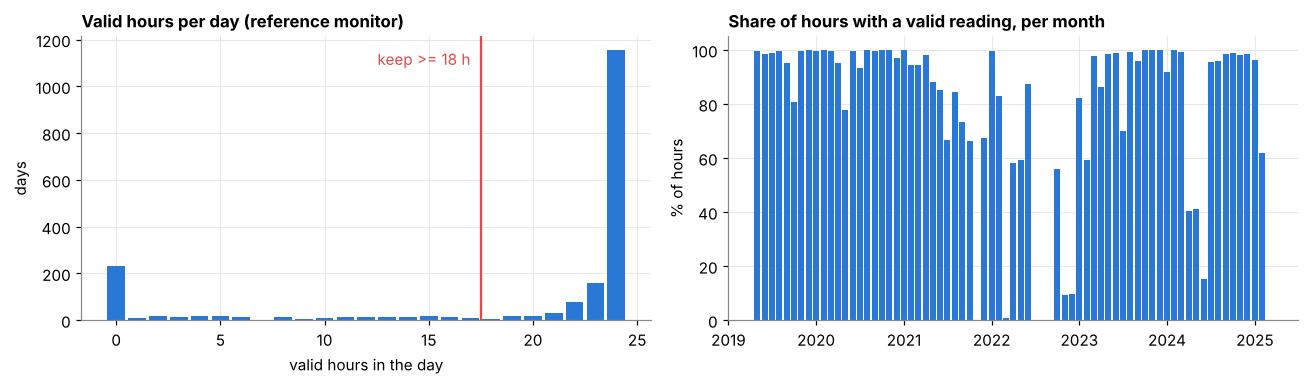

Days with data: 1,909 | kept (>= 18 h): 1,464 | dropped: 445


In [16]:
g = ref.groupby("date")["value"]
ref_daily = pd.DataFrame({"mean": g.mean(), "max": g.max(), "n_hours": g.count()})
ok = ref_daily.n_hours >= MIN_HOURS
log_step("reference daily", f"days with < {MIN_HOURS} valid hours set to missing", len(ref_daily), len(ref_daily), int((~ok).sum()))
ref_daily.loc[~ok, ["mean", "max"]] = np.nan

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
axes[0].hist(ref_daily.n_hours, bins=np.arange(-0.5, 25.5, 1), color=BLUE, rwidth=0.85)
axes[0].axvline(MIN_HOURS - 0.5, color=RED, lw=1.5)
axes[0].text(MIN_HOURS - 1, axes[0].get_ylim()[1] * 0.9, f"keep >= {MIN_HOURS} h", ha="right", color=RED)
axes[0].set(title="Valid hours per day (reference monitor)", xlabel="valid hours in the day", ylabel="days")

monthly = ref.set_index("dt_end")["value"].notna().groupby(pd.Grouper(freq="MS")).mean() * 100
axes[1].bar(monthly.index, monthly.values, width=25, color=BLUE)
axes[1].set(title="Share of hours with a valid reading, per month", ylabel="% of hours", ylim=(0, 105))
nice_dates(axes[1])
fig.tight_layout(); savefig(fig, "01_reference_completeness")
print(f"Days with data: {len(ref_daily):,} | kept (>= {MIN_HOURS} h): {int(ok.sum()):,} | dropped: {int((~ok).sum()):,}")

**Discussion:**
- Most days are either complete (24 h) or nearly empty. The 18-hour rule therefore removes the broken days without throwing away good ones.
- The monthly chart shows the **outages** clearly. There are long gaps from **late 2021 to early 2023** (several months with no data at all) and a weak spell in **spring 2024**, and the monitor **stops completely in March 2025**.
- This is why we also need the low-cost sensors (Section 4.2): they fill the period after the US monitor stopped.

## 4.2 Low-cost sensors (daily, per sensor)
These are cheap optical sensors (AirGradient, Hawanama and Clarity) spread across the city. We clean them in four steps:
1. **Incomplete days:** keep a sensor-day only if it has at least 18 hourly readings.
2. **Impossible values:** a daily mean ≤ 0 or ≥ 1,500 µg/m³.
3. **Test devices:** any location whose name contains "test".
4. **Outliers:** a robust, *relative* rule. On days with at least 5 sensors, a sensor reading **more than 3× or less than ⅓ of the city median** is removed. A fixed cut-off such as "above 500" would wrongly delete real smog days; comparing a sensor with its neighbours on the *same day* only catches faulty sensors.

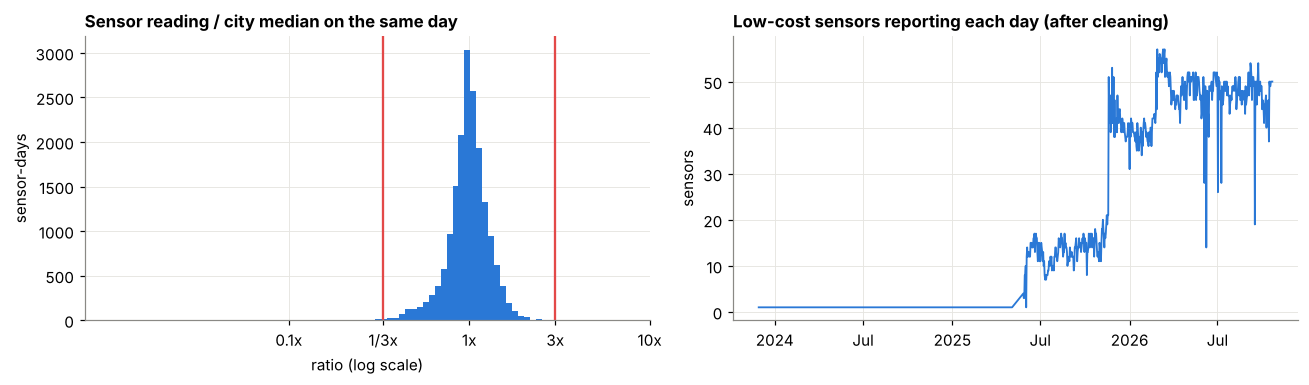

Sensor-days kept: 18,195 from 80 locations (outliers removed: 63, i.e. 0.35 %)


In [17]:
lc = lc_raw.copy()
lc["date"] = pd.to_datetime(lc["date"], format="%Y-%m-%d")
lc = lc.merge(locs_raw[["location_id", "name", "provider", "lat", "lon"]], on="location_id", how="left")

n = len(lc); lc = lc[lc.observed_hours >= MIN_HOURS]
log_step("low-cost daily", f"sensor-days with < {MIN_HOURS} hourly readings removed", n, len(lc))
n = len(lc); lc = lc[(lc["mean"] > 0) & (lc["mean"] < 1500)]
log_step("low-cost daily", "impossible daily means (<= 0 or >= 1500) removed", n, len(lc))
n = len(lc); lc = lc[~lc["name"].astype(str).str.contains("test", case=False)]
log_step("low-cost daily", "'test' devices removed", n, len(lc))

day_median = lc.groupby("date")["mean"].transform("median")
day_count  = lc.groupby("date")["mean"].transform("count")
ratio = lc["mean"] / day_median
outlier = (day_count >= 5) & ((ratio > 3) | (ratio < 1 / 3))
n = len(lc); lc_before_outliers = lc.assign(ratio=ratio, outlier=outlier); lc = lc[~outlier]
log_step("low-cost daily", "outliers removed (> 3x or < 1/3 of the city median, days with >= 5 sensors)", n, len(lc))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
r = lc_before_outliers.loc[day_count >= 5, "ratio"]
axes[0].hist(np.log10(r.clip(0.01, 100)), bins=80, color=BLUE)
for x in (1 / 3, 3):
    axes[0].axvline(np.log10(x), color=RED, lw=1.5)
axes[0].set_xticks(np.log10([0.1, 1 / 3, 1, 3, 10]), ["0.1x", "1/3x", "1x", "3x", "10x"])
axes[0].set(title="Sensor reading / city median on the same day", xlabel="ratio (log scale)", ylabel="sensor-days")
active = lc.groupby("date")["location_id"].nunique()
axes[1].plot(active.index, active.values, color=BLUE, lw=1.2)
axes[1].set(title="Low-cost sensors reporting each day (after cleaning)", ylabel="sensors")
nice_dates(axes[1])
fig.tight_layout(); savefig(fig, "02_lowcost_cleaning")
print(f"Sensor-days kept: {len(lc):,} from {lc.location_id.nunique()} locations "
      f"(outliers removed: {int(outlier.sum())}, i.e. {100 * outlier.sum() / n:.2f} %)")

**Discussion:**
- Almost all sensor-days sit close to **1×** the city median, so the sensors agree well with each other.
- The red lines mark the outlier rule. Only a very small share of sensor-days lies outside them, and those are typical faults: a sensor reading near zero, or a sensor next to a local source.
- The right-hand chart shows that until **May 2025** only one low-cost sensor (Clarity) was reporting. The network then grows to about **15 sensors**, and to **40–55** from November 2025. Because the US monitor stopped in March 2025, this network is our only PM2.5 source for the 2025–26 winter.

## 4.3 Weather (ERA5, hourly)
ERA5 is a quality-controlled reanalysis, so we mainly *check* it here:
- duplicate hours;
- physically valid ranges;
- missing values.

We do not change values.

In [18]:
wx = wx_raw.copy()
wx["time"] = pd.to_datetime(wx["time"], format="%Y-%m-%dT%H:%M")       # already Pakistan local time
n = len(wx); wx = wx.drop_duplicates(["site", "time"])
log_step("weather hourly", "duplicate (site, hour) rows removed", n, len(wx))

checks = {"temperature_2m": (-15, 55), "relative_humidity_2m": (0, 100), "precipitation": (0, 300),
          "pressure_msl": (950, 1060), "cloud_cover": (0, 100), "wind_speed_10m": (0, 150),
          "wind_direction_10m": (0, 360), "wind_direction_100m": (0, 360), "boundary_layer_height": (0, 6000)}
range_check = pd.DataFrame([{"variable": c, "min": wx[c].min(), "max": wx[c].max(), "allowed": f"{lo} to {hi}",
                             "out of range": int(((wx[c] < lo) | (wx[c] > hi)).sum()),
                             "missing %": round(100 * wx[c].isna().mean(), 2)} for c, (lo, hi) in checks.items()])
display(range_check)

blh_missing = wx[wx.site == "lahore"].set_index("time")["boundary_layer_height"].isna().groupby(pd.Grouper(freq="MS")).sum()
blh_missing = blh_missing[blh_missing > 0]
print("Lahore: months with missing boundary-layer height (hours missing):")
print(blh_missing.to_string())

,variable,min,max,allowed,out of range,missing %
0,temperature_2m,1.90,47.30,-15 to 55,0,0.09
1,relative_humidity_2m,3.00,100.00,0 to 100,0,0.09
2,precipitation,0.00,30.70,0 to 300,0,0.09
3,pressure_msl,987.80,"1,029.50",950 to 1060,0,0.09
4,cloud_cover,0.00,100.00,0 to 100,0,0.09
5,wind_speed_10m,0.00,40.10,0 to 150,0,0.09
6,wind_direction_10m,1.00,360.00,0 to 360,0,0.09
7,wind_direction_100m,0.00,360.00,0 to 360,0,0.09
8,boundary_layer_height,10.00,"5,165.00",0 to 6000,0,3.45


Lahore: months with missing boundary-layer height (hours missing):
time
2024-01-01    739
2024-02-01    696
2024-03-01    744
2024-04-01    720
2024-05-01    744
2024-06-01    720
2024-07-01      5
2026-10-01    115


**Discussion:** all variables are within physical limits and there are no duplicates. The one real problem is **boundary-layer height (BLH)**, which is missing from **January to June 2024** (a gap in the ERA5 product) and for the last few days before the snapshot.

BLH matters: it is the height of the air layer in which pollution can mix, so a low BLH means smog is trapped near the ground. We therefore **do not drop** those months. In Section 5.6 we fill them with a climatology and add a flag column.

## 4.4 Fire detections (NASA FIRMS, VIIRS)
1. **Duplicates:** the same pixel, satellite and time reported twice.
2. **Low confidence** (`confidence = l`): often sun glint or a hot surface, not a fire.
3. **Type 2 and 3:** static land sources (brick kilns, factories) and offshore detections. They burn all year, so they are not crop fires.
4. **Time zone:** FIRMS times are UTC. We add 5 hours to get Pakistan time *before* assigning the date, because a night overpass at 21:00 UTC belongs to the next local day.
5. **Country:** for the 2026 API rows, which have no country, we assign Pakistan or India by comparing the longitude with an approximate border line through Punjab.

In [19]:
fires = fires_raw.copy()
n = len(fires); fires = fires.drop_duplicates(["sensor", "latitude", "longitude", "acq_date", "acq_time"])
log_step("fires", "duplicate detections removed", n, len(fires))
conf_counts = fires.confidence.str.lower().str[0].value_counts()
n = len(fires); fires = fires[fires.confidence.str.lower().str[0] != "l"]
log_step("fires", "low-confidence detections removed", n, len(fires))
n = len(fires); fires = fires[~fires["type"].isin(["2", "3"])]
log_step("fires", "static land sources / offshore (type 2, 3) removed", n, len(fires))

t = fires["acq_time"].str.zfill(4)
fires["utc"] = pd.to_datetime(fires["acq_date"] + " " + t.str[:2] + ":" + t.str[2:], format="%Y-%m-%d %H:%M")
fires["date"] = (fires["utc"] + pd.Timedelta(hours=5)).dt.normalize()          # Pakistan local date
fires["frp"] = pd.to_numeric(fires["frp"], errors="coerce")

# approximate Pakistan-India border in the Punjab sector (lat, lon); east of the line = India
BORDER = [(28.0, 71.9), (29.0, 72.95), (29.9, 73.4), (30.4, 73.9), (31.0, 74.54), (31.6, 74.57),
          (32.05, 74.95), (32.3, 75.35), (32.5, 74.75), (34.5, 74.6)]
border_lon = np.interp(fires.latitude, [b[0] for b in BORDER], [b[1] for b in BORDER])
no_country = fires["country"].isna() | (fires["country"].astype(str).isin(["", "nan"]))
fires.loc[no_country, "country"] = np.where(fires.loc[no_country, "longitude"] < border_lon[no_country.values], "Pakistan", "India")
log_step("fires", "country assigned from the border line (2026 API rows)", len(fires), len(fires), int(no_country.sum()))

print("Confidence before cleaning:", {"low": int(conf_counts.get("l", 0)), "nominal": int(conf_counts.get("n", 0)),
                                       "high": int(conf_counts.get("h", 0))})
print(f"Detections kept: {len(fires):,}  |  by satellite: " + ", ".join(f"{k} {v:,}" for k, v in fires.sensor.value_counts().items()))
print("Spot check: night detection at 21:30 UTC on 2023-11-04 ->",
      (pd.Timestamp("2023-11-04 21:30") + pd.Timedelta(hours=5)).date(), "local date")

del fires_raw, RAW          # free ~1.3 GB of memory (to re-run this cell, re-run Section 3.1 first)

Confidence before cleaning: {'low': 431232, 'nominal': 2737591, 'high': 106132}
Detections kept: 2,780,460  |  by satellite: SNPP 1,791,284, N20 989,176
Spot check: night detection at 21:30 UTC on 2023-11-04 -> 2023-11-05 local date


## 4.5 Cleaning summary
Every cleaning step and the number of rows it affected:

In [20]:
clean_log = pd.DataFrame(CLEAN_LOG)
clean_log.to_csv(OUT_DIR / "cleaning_log.csv", index=False)
clean_log

,dataset,step,rows before,rows after,rows affected
0,reference hourly,"invalid values (-999, negative, >1500) set to ...",44516,44516,8107
1,reference hourly,duplicate hours removed,44516,44516,0
2,reference daily,days with < 18 valid hours set to missing,1909,1909,445
3,low-cost daily,sensor-days with < 18 hourly readings removed,21821,18258,3563
4,low-cost daily,impossible daily means (<= 0 or >= 1500) removed,18258,18258,0
5,low-cost daily,'test' devices removed,18258,18258,0
6,low-cost daily,outliers removed (> 3x or < 1/3 of the city me...,18258,18195,63
7,weather hourly,"duplicate (site, hour) rows removed",389448,389448,0
8,fires,duplicate detections removed,3274955,3274955,0
9,fires,low-confidence detections removed,3274955,2843723,431232


**Discussion:**
- The biggest single cleaning effect is on the **reference monitor**: about 8,100 invalid hours. Together with the 18-hour rule, that leaves **1,464 trusted reference days**.
- For the **fires**, roughly 15 % of detections are dropped, mostly low-confidence ones. This makes the fire counts a cleaner index of real crop burning.
- **Nothing is invented at this stage.** Missing values stay missing until Section 5.6, where we decide carefully what may be filled and what may not.

# 5. Preprocessing and transformations
Our prediction unit is **one day in Lahore**, so all sources have to be brought to the same daily grid, in Pakistan local time. Here we:

1. combine the low-cost sensors into one city value per day (5.1);
2. turn hourly weather into daily weather, averaging wind **direction** correctly as a vector (5.2);
3. **calibrate** the low-cost sensors to the reference monitor's scale (5.3);
4. merge everything into one continuous daily PM2.5 series (5.4);
5. compute each fire's **distance and direction** from Lahore, and whether it is **upwind** (5.5);
6. handle the remaining missing values and check skewness and angles (5.6–5.7).

## 5.1 Low-cost network: one value per day
For each day we take the **median** across all low-cost sensors (excluding Clarity, which is used separately for calibration). The median is robust: one bad sensor cannot move it much.

We only trust the network value on days with **at least 5 sensors**.

In [21]:
clarity = lc[lc.location_id == CLARITY_ID].set_index("date")["mean"].rename("clarity")
network = lc[lc.location_id != CLARITY_ID]
city = network.groupby("date")["mean"].agg(lc_median="median", lc_n="count")
print(f"Clarity sensor days: {clarity.size:,} ({clarity.index.min().date()} to {clarity.index.max().date()})")
print(f"Network days: {len(city):,}; days with >= 5 sensors: {int((city.lc_n >= 5).sum()):,}")

Clarity sensor days: 647 (2023-11-29 to 2026-08-31)
Network days: 512; days with >= 5 sensors: 509


## 5.2 Weather: hourly to daily (vector-averaged wind)
Temperature, humidity, pressure, cloud and BLH are simple daily **means**; rain is the daily **sum**.

**Wind direction cannot be averaged like a normal number.** The arithmetic mean of 350° and 10° is 180° (south), but both winds come from the *north* (0°). We therefore turn each hourly wind into a vector with east and north components (u, v), average the vectors, and convert back to a direction. The cell first demonstrates this on that tiny example.

In [22]:
def vector_mean_wind(speed, direction_deg):
    "Average wind as vectors. Returns (resultant speed, direction the wind blows FROM in degrees)."
    rad = np.radians(direction_deg)
    u, v = -(speed * np.sin(rad)).mean(), -(speed * np.cos(rad)).mean()
    return np.hypot(u, v), (np.degrees(np.arctan2(-u, -v)) + 360) % 360

spd, d = vector_mean_wind(np.array([10.0, 10.0]), np.array([350.0, 10.0]))
print(f"Example: winds from 350 deg and 10 deg -> arithmetic mean = 180 deg (wrong), vector mean = {d:.0f} deg (north, correct)")

def weather_daily(w):
    "Hourly ERA5 rows of one site -> one row per local day."
    w = w.assign(date=w["time"].dt.normalize())
    for h in ("10m", "100m"):                                 # hourly wind vectors (NaN if speed or direction is missing)
        rad = np.radians(w[f"wind_direction_{h}"])
        w[f"u{h}"] = -w[f"wind_speed_{h}"] * np.sin(rad)
        w[f"v{h}"] = -w[f"wind_speed_{h}"] * np.cos(rad)
    g = w.groupby("date")
    d = pd.DataFrame({
        "temp_mean": g.temperature_2m.mean(), "temp_max": g.temperature_2m.max(),
        "rh_mean": g.relative_humidity_2m.mean(), "precip_sum": g.precipitation.sum(min_count=1),
        "pressure_mean": g.pressure_msl.mean(), "cloud_mean": g.cloud_cover.mean(),
        "blh_mean": g.boundary_layer_height.mean(),
    })
    for h in ("10m", "100m"):
        u, v = g[f"u{h}"].mean(), g[f"v{h}"].mean()
        d[f"wind{h[:-1]}_speed"] = np.hypot(u, v)
        d[f"wind{h[:-1]}_dir"] = (np.degrees(np.arctan2(-u, -v)) + 360) % 360
    return d

wx_lahore = weather_daily(wx[wx.site == "lahore"].copy())
print(f"Lahore daily weather: {len(wx_lahore):,} days ({wx_lahore.index.min().date()} to {wx_lahore.index.max().date()}); "
      f"days without BLH: {int(wx_lahore.blh_mean.isna().sum())}")
wx_lahore.head()

Example: winds from 350 deg and 10 deg -> arithmetic mean = 180 deg (wrong), vector mean = 0 deg (north, correct)
Lahore daily weather: 5,409 days (2012-01-01 to 2026-10-22); days without BLH: 185


,temp_mean,temp_max,rh_mean,precip_sum,pressure_mean,cloud_mean,blh_mean,wind10_speed,wind10_dir,wind100_speed,wind100_dir
date,,,,,,,,,,,
2012-01-01,11.68,19.80,74.00,0.00,"1,016.39",0.00,228.12,4.79,308.65,7.55,312.97
2012-01-02,11.92,20.00,74.00,0.00,"1,016.60",26.12,252.08,2.93,236.38,4.05,260.26
2012-01-03,11.84,20.50,70.88,0.00,"1,015.23",3.21,221.88,6.27,279.61,9.14,291.24
2012-01-04,12.12,17.80,74.33,1.30,"1,014.59",63.58,203.12,2.46,112.35,2.52,124.24
2012-01-05,12.29,19.00,80.12,0.00,"1,015.85",17.21,210.21,4.56,86.63,6.37,98.27


## 5.3 Calibration: putting low-cost sensors on the reference scale
Low-cost optical sensors do **not** read the same as a reference monitor; humidity and particle type bias them. If we simply joined the two series, the target would jump in March 2025, when the source switches, and a model would learn that artefact.

The sensors never overlap the US monitor directly. They do overlap the **Clarity** sensor, and Clarity overlaps the monitor, so we use a **chain of two linear fits**:

1. **reference ≈ a₁ + b₁ · Clarity**, fitted on days when both report (Nov 2023 – Mar 2025);
2. **Clarity ≈ a₂ + b₂ · network median**, fitted on days when both report (May 2025 – Sep 2026);

which gives **reference-equivalent = a₁ + b₁ · (a₂ + b₂ · network median)**.

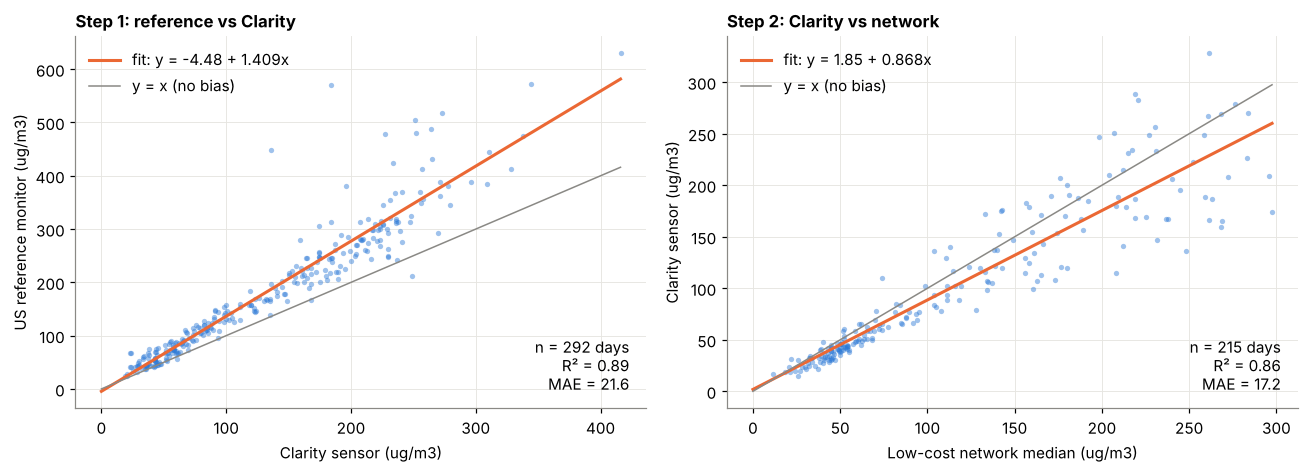

Chained calibration: reference-equivalent = -4.48 + 1.409 x (1.85 + 0.868 x network median)  =  -1.87 + 1.223 x network median
Example: a network median of 100 ug/m3 -> 120 ug/m3 on the reference scale


In [23]:
def linear_fit(x, y):
    m = pd.concat([x, y], axis=1, sort=True).dropna()
    X, Y = m.iloc[:, 0].to_numpy(), m.iloc[:, 1].to_numpy()
    b, a = np.polyfit(X, Y, 1)
    pred = a + b * X
    r2 = 1 - ((Y - pred) ** 2).sum() / ((Y - Y.mean()) ** 2).sum()
    return {"a": a, "b": b, "n": len(m), "r2": r2, "mae": np.abs(Y - pred).mean(), "x": X, "y": Y}

ref_mean = ref_daily["mean"].rename("reference")
fit1 = linear_fit(clarity, ref_mean)                                   # reference ~ Clarity
fit2 = linear_fit(city.loc[city.lc_n >= 1, "lc_median"], clarity)      # Clarity ~ network median

fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
for ax, f, xl, yl, title in [(axes[0], fit1, "Clarity sensor (ug/m3)", "US reference monitor (ug/m3)", "Step 1: reference vs Clarity"),
                             (axes[1], fit2, "Low-cost network median (ug/m3)", "Clarity sensor (ug/m3)", "Step 2: Clarity vs network")]:
    ax.scatter(f["x"], f["y"], s=12, alpha=0.45, color=BLUE, linewidths=0)
    xs = np.linspace(0, f["x"].max(), 50)
    ax.plot(xs, f["a"] + f["b"] * xs, color=ORANGE, lw=2, label=f"fit: y = {f['a']:.2f} + {f['b']:.3f}x")
    ax.plot(xs, xs, color=GREY, lw=1, label="y = x (no bias)")
    ax.set(title=title, xlabel=xl, ylabel=yl)
    ax.legend(loc="upper left")
    ax.text(0.97, 0.05, f"n = {f['n']} days\nR² = {f['r2']:.2f}\nMAE = {f['mae']:.1f}", transform=ax.transAxes, ha="right")
fig.tight_layout(); savefig(fig, "03_calibration")

a1, b1, a2, b2 = fit1["a"], fit1["b"], fit2["a"], fit2["b"]
city["lc_calibrated"] = a1 + b1 * (a2 + b2 * city["lc_median"])
clarity_cal = a1 + b1 * clarity
print(f"Chained calibration: reference-equivalent = {a1:.2f} + {b1:.3f} x ({a2:.2f} + {b2:.3f} x network median)"
      f"  =  {a1 + b1 * a2:.2f} + {b1 * b2:.3f} x network median")
print(f"Example: a network median of 100 ug/m3 -> {a1 + b1 * (a2 + b2 * 100):.0f} ug/m3 on the reference scale")

**Discussion:**
- Both fits are strong: **R² = 0.89** and **0.86**.
- Both slopes differ from 1. Clarity reads about **30 % lower** than the reference monitor (slope 1.41). The network reads about 15 % higher than Clarity (slope 0.87), so after chaining, a raw network value has to be multiplied by about **1.22**.
- **Without calibration, the 2025–26 winter would look about 18 % cleaner than it really was.**
- A linear fit has its limits: the scatter grows at very high values. We will therefore always evaluate the model separately on reference days and on calibrated days; the column `sensor_type_tomorrow` makes this easy.

## 5.4 One continuous daily PM2.5 series
For each day, PM2.5 is taken from the best available source, in this order of priority:

1. **US reference monitor** (if the day has at least 18 valid hours);
2. else the **calibrated low-cost network** (if at least 5 sensors reported);
3. else the **calibrated Clarity sensor**;
4. else **missing**: we never invent a target value.

In [24]:
days = pd.date_range(START, END, freq="D")
daily = pd.DataFrame(index=pd.Index(days, name="date"))
daily["pm25_ref"] = ref_daily["mean"]
daily["pm25_ref_max"] = ref_daily["max"]
daily["pm25_clarity_cal"] = clarity_cal
daily["pm25_network_cal"] = city["lc_calibrated"]
daily["n_lowcost_sensors"] = city["lc_n"]

use_net = daily.pm25_ref.isna() & (daily.n_lowcost_sensors >= 5)
use_cla = daily.pm25_ref.isna() & ~use_net & daily.pm25_clarity_cal.notna()
daily["pm25"] = daily["pm25_ref"]
daily.loc[use_net, "pm25"] = daily.loc[use_net, "pm25_network_cal"]
daily.loc[use_cla, "pm25"] = daily.loc[use_cla, "pm25_clarity_cal"]
daily["pm25_source"] = np.select([daily.pm25_ref.notna(), use_net, use_cla],
                                 ["reference", "lowcost_calibrated", "clarity_calibrated"], "missing")

print(daily["pm25_source"].value_counts().to_string())
print(f"\nSanity check - 15 Nov 2023 (a reference day): {daily.loc['2023-11-15', 'pm25']:.3f} ug/m3")

pm25_source
reference             1464
missing                597
lowcost_calibrated     509
clarity_calibrated     140

Sanity check - 15 Nov 2023 (a reference day): 173.667 ug/m3


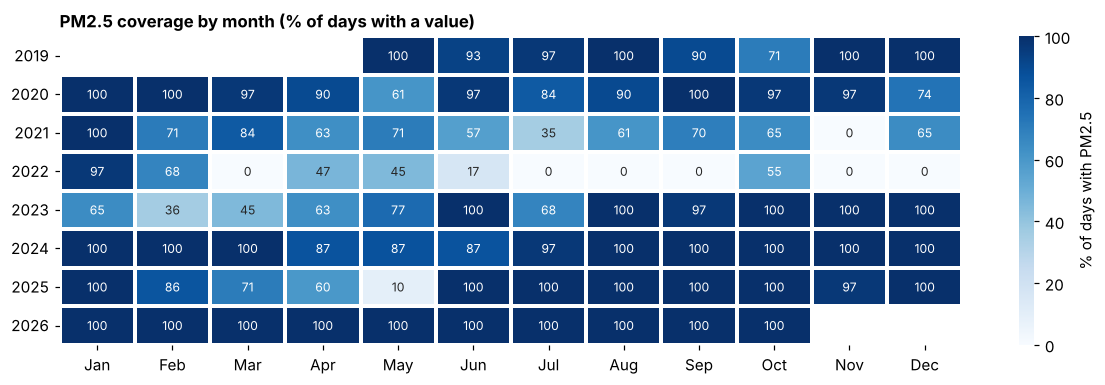

In [25]:
cov = daily["pm25"].notna().groupby([daily.index.year, daily.index.month]).mean().unstack() * 100
cov.columns = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
fig, ax = plt.subplots(figsize=(11, 3.6))
sns.heatmap(cov, cmap="Blues", vmin=0, vmax=100, annot=True, fmt=".0f", annot_kws={"size": 8},
            cbar_kws={"label": "% of days with PM2.5"}, linewidths=1.5, linecolor="white", ax=ax)
ax.set(title="PM2.5 coverage by month (% of days with a value)", xlabel="", ylabel="")
ax.tick_params(axis="y", rotation=0)
ax.grid(False)
fig.tight_layout(); savefig(fig, "04_pm25_coverage")

**Discussion:**
- Coverage is complete or nearly complete in most months. The big holes come from **US-monitor outages**: November 2021 is missing entirely, most of 2022 is empty (including **November and December 2022**), and early 2023 is patchy. There is also a gap in **spring 2025**, when the US monitor had stopped and the low-cost network had not yet started.
- **The target is never filled.** The model simply has no training rows on those days, which is the honest choice. As a result, winters 2021–22 and 2022–23 contribute fewer training days.
- **From mid-2023 onwards** coverage is almost 100 %, which is why the most recent winters, 2024–25 and 2025–26, are used for testing.

## 5.5 Fire geometry: distance, direction and upwind fires
For every fire detection we compute:
- **distance** from Lahore, using the haversine great-circle formula;
- **bearing**, the compass direction from Lahore to the fire (0° = north, 90° = east);
- whether it is **upwind**: a fire whose bearing lies within **±45°** of the direction the 100 m wind blows *from* that day. Smoke from such a fire is carried *towards* Lahore.

We use the **NOAA-20** satellite for the Lahore features (available since 2018, continuing after 2026). **S-NPP**, available since 2012, is used for the long-term regional trends in the EDA.

In [26]:
def haversine_km(lat1, lon1, lat2, lon2):
    p = np.pi / 180
    a = np.sin((lat2 - lat1) * p / 2) ** 2 + np.cos(lat1 * p) * np.cos(lat2 * p) * np.sin((lon2 - lon1) * p / 2) ** 2
    return 12742 * np.arcsin(np.sqrt(a))

def bearing_deg(lat1, lon1, lat2, lon2):
    p = np.pi / 180
    y = np.sin((lon2 - lon1) * p) * np.cos(lat2 * p)
    x = np.cos(lat1 * p) * np.sin(lat2 * p) - np.sin(lat1 * p) * np.cos(lat2 * p) * np.cos((lon2 - lon1) * p)
    return (np.degrees(np.arctan2(y, x)) + 360) % 360

fires["dist_km"] = haversine_km(LAHORE_LAT, LAHORE_LON, fires.latitude.to_numpy(), fires.longitude.to_numpy())
fires["bearing"] = bearing_deg(LAHORE_LAT, LAHORE_LON, fires.latitude.to_numpy(), fires.longitude.to_numpy())
fires = fires.merge(wx_lahore["wind100_dir"].rename("wind_from").reset_index(), on="date", how="left")
angle_diff = np.abs(((fires["bearing"] - fires["wind_from"]) + 180) % 360 - 180)   # smallest angle between the two
fires["upwind"] = angle_diff <= 45

print("Check: Amritsar (31.63N, 74.87E) is", round(float(haversine_km(LAHORE_LAT, LAHORE_LON, 31.63, 74.87))), "km from Lahore at bearing",
      round(float(bearing_deg(LAHORE_LAT, LAHORE_LON, 31.63, 74.87))), "deg (east) - as expected")

n20 = fires[(fires.sensor == "N20") & (fires.dist_km <= FIRE_RADIUS_KM)]
fire_daily = pd.DataFrame({
    "fires_300km": n20.groupby("date").size(),
    "frp_300km": n20.groupby("date")["frp"].sum(),
    "fires_upwind_300km": n20[n20.upwind].groupby("date").size(),
    "fires_pk_300km": n20[n20.country == "Pakistan"].groupby("date").size(),
    "fires_in_300km": n20[n20.country == "India"].groupby("date").size(),
})
print(f"NOAA-20 detections within {FIRE_RADIUS_KM} km of Lahore: {len(n20):,} on {fire_daily.shape[0]:,} days; "
      f"upwind share: {100 * n20.upwind.mean():.1f} %")

Check: Amritsar (31.63N, 74.87E) is 51 km from Lahore at bearing 81 deg (east) - as expected
NOAA-20 detections within 300 km of Lahore: 825,662 on 3,019 days; upwind share: 19.1 %


**Regional fire table (for the EDA).** Daily fire counts in **Pakistani Punjab** and **Indian Punjab + Haryana**, from S-NPP for the long 2012–2026 record:

In [27]:
snpp = fires[fires.sensor == "SNPP"]
pk_mask = (snpp.country == "Pakistan") & snpp.latitude.between(28.0, 33.0) & (snpp.longitude < 75.4)
in_mask = (snpp.country == "India") & snpp.latitude.between(28.5, 32.6) & snpp.longitude.between(73.8, 77.6)
regional = pd.DataFrame({"pakistan_punjab": snpp[pk_mask].groupby("date").size(),
                         "india_punjab_haryana": snpp[in_mask].groupby("date").size()})
regional = regional.reindex(pd.date_range("2012-01-20", END, freq="D")).fillna(0).astype(int)
regional.index.name = "date"
print(f"Regional table: {len(regional):,} days; total detections: Pakistan {int(regional.pakistan_punjab.sum()):,}, "
      f"India {int(regional.india_punjab_haryana.sum()):,}")

Regional table: 5,390 days; total detections: Pakistan 496,506, India 1,185,055


## 5.6 Assemble the daily table and handle the remaining missing values
We join PM2.5, weather and fire features on the date. The remaining gaps are handled by these rules, which are designed to **avoid data leakage and invented targets**:

| Gap | Rule | Why |
|---|---|---|
| No fire detected on a day | **0 fires** | No detection means no (visible) fire, so this is not missing data |
| Upwind fires when the wind direction is unknown | left **missing** | "Upwind" is undefined without the wind |
| **Target** (tomorrow's PM2.5) missing | **row dropped**, never filled | Filling the target would make the model learn our own guesses |
| Past PM2.5 used as an **input**, short gap (≤ 2 days) | **linear interpolation**, flagged in `pm25_today_was_filled` | A 1–2 day gap is well bridged by its neighbours; longer gaps are not |
| Boundary-layer height (ERA5 gap Jan–Jun 2024) | **same calendar day's average over other years**, flagged | Keeps 185 days of training data; the flag lets the model and us check its effect |
| Anything still missing | row dropped | Usually right after a long outage, when "yesterday" or "last 7 days" is unknown |

First, how long are the PM2.5 gaps? This tells us how much a ≤ 2-day interpolation can safely fix.

In [28]:
daily = daily.join(wx_lahore).join(fire_daily)
for c in fire_daily.columns:
    daily[c] = daily[c].fillna(0)
daily.loc[daily.wind100_dir.isna(), "fires_upwind_300km"] = np.nan

# --- length of every run of missing PM2.5 days
is_na = daily["pm25"].isna()
run_id = (is_na != is_na.shift()).cumsum()
run_len = is_na.groupby(run_id).transform("sum").where(is_na)
runs = run_len[is_na].groupby(run_id[is_na]).first()
bins = pd.cut(runs, [0, 1, 2, 7, 30, 1000], labels=["1 day", "2 days", "3-7 days", "8-30 days", "> 30 days"])
gap_table = pd.DataFrame({"gaps": bins.value_counts(sort=False),
                          "missing days": runs.groupby(bins, observed=False).sum()})
print(f"Missing PM2.5 days: {int(is_na.sum())} of {len(daily)} ({100 * is_na.mean():.1f} %) in {len(runs)} gaps")
gap_table

Missing PM2.5 days: 597 of 2710 (22.0 %) in 118 gaps


,gaps,missing days
pm25,,
1 day,61,61.00
2 days,19,38.00
3-7 days,26,102.00
8-30 days,8,118.00
> 30 days,4,278.00


In [29]:
# --- inputs only: fill PM2.5 gaps of at most 2 days (whole gap must be <= 2 days), and flag them
short_gap = is_na & (run_len <= 2)
pm25_input = daily["pm25"].interpolate(method="linear", limit_area="inside").where(~is_na | short_gap)
daily["pm25_input"] = pm25_input
daily["pm25_input_filled"] = (short_gap & pm25_input.notna()).astype(int)

# --- boundary-layer height: climatology of the same calendar day, flagged
blh_gap = daily["blh_mean"].isna()
blh_clim = wx_lahore["blh_mean"].groupby(wx_lahore.index.dayofyear).mean()     # 2012-2026 average per calendar day
daily["blh_filled"] = daily["blh_mean"].fillna(pd.Series(daily.index.dayofyear.map(blh_clim), index=daily.index))
daily["blh_was_filled"] = blh_gap.astype(int)

print(f"PM2.5 input days filled by interpolation: {int(daily.pm25_input_filled.sum())} (targets untouched)")
print(f"Boundary-layer height filled with climatology: {int(blh_gap.sum())} days")
print(f"Upwind-fire feature unknown (no wind direction yet): {int(daily.fires_upwind_300km.isna().sum())} days")

PM2.5 input days filled by interpolation: 99 (targets untouched)
Boundary-layer height filled with climatology: 185 days
Upwind-fire feature unknown (no wind direction yet): 4 days


## 5.7 Transformations: skewness and angles
**Skewness.** PM2.5, fire counts, fire power and rain all have long right tails. The table compares the skewness of each variable before and after a `log1p` transform, log(1 + x), which works with zeros.

**Decision:** we keep the raw values in the dataset, because tree-based models (our Phase-2 choice) are not affected by monotone transforms. We do note `log1p` as the transform to use for any linear model.

**Angles.** Wind direction is circular: 359° and 1° are neighbours but numerically far apart. We encode it as **sin** and **cos** components so that a model sees the circle correctly.

,variable,skew (raw),skew (log1p)
0,PM2.5 (ug/m3),1.44,0.09
1,fires within 300 km,5.14,-0.09
2,fire power within 300 km (MW),5.80,-0.38
3,daily rain (mm),6.96,2.26
4,boundary-layer height (m),0.91,-0.27


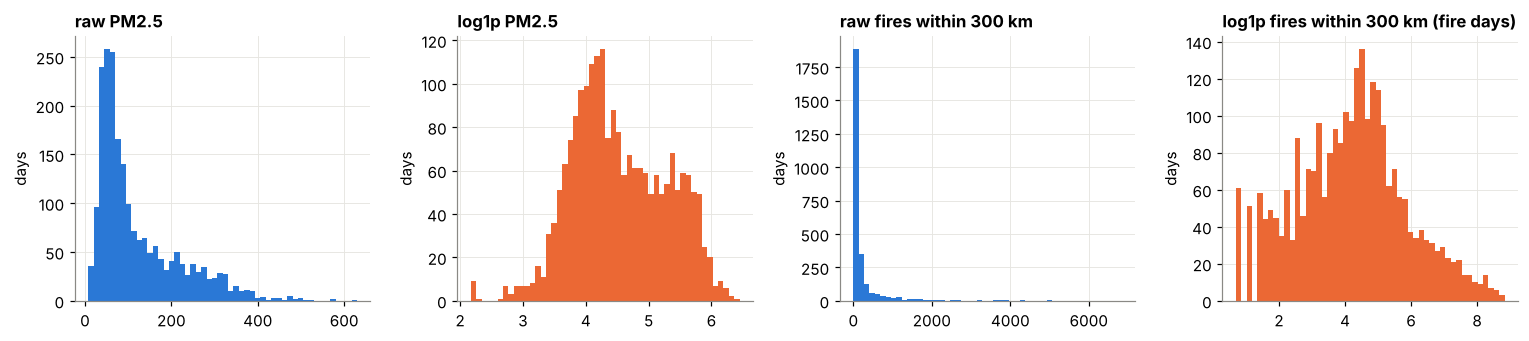

In [30]:
skew_cols = {"pm25": "PM2.5 (ug/m3)", "fires_300km": "fires within 300 km", "frp_300km": "fire power within 300 km (MW)",
             "precip_sum": "daily rain (mm)", "blh_filled": "boundary-layer height (m)"}
skew = pd.DataFrame({"variable": list(skew_cols.values()),
                     "skew (raw)": [daily[c].skew() for c in skew_cols],
                     "skew (log1p)": [np.log1p(daily[c].clip(lower=0)).skew() for c in skew_cols]}).round(2)
display(skew)

fig, axes = plt.subplots(1, 4, figsize=(14, 3.2))
for ax, (c, lab), tf in zip(axes, [("pm25", "PM2.5"), ("pm25", "PM2.5"), ("fires_300km", "fires within 300 km"),
                                    ("fires_300km", "fires within 300 km")], [False, True, False, True]):
    x = daily[c].dropna()
    x = x[x > 0] if (tf and c == "fires_300km") else x
    ax.hist(np.log1p(x) if tf else x, bins=50, color=ORANGE if tf else BLUE)
    ax.set(title=("log1p " if tf else "raw ") + lab + (" (fire days)" if tf and c == "fires_300km" else ""), ylabel="days")
fig.tight_layout(); savefig(fig, "05_skewness")

daily["wind_dir_sin"] = np.sin(np.radians(daily["wind100_dir"]))
daily["wind_dir_cos"] = np.cos(np.radians(daily["wind100_dir"]))

**Discussion:**
- **Fire counts and fire power are extremely skewed** (skew above 5): on most days only a handful to a few dozen fires are detected within 300 km, but a few November days have **thousands**. **Rain** is similar: almost always 0, with occasional heavy days. **PM2.5** is moderately skewed (1.4).
- After `log1p`, PM2.5 becomes almost symmetric (skew 0.1), and so do the fire counts. A linear model would therefore need this transform.
- Tree-based models only use the *order* of values, so they handle the raw values directly. This is one more reason to use gradient boosting in Phase 2.

# 6. Feature engineering and feature selection
## 6.1 The forecasting set-up and the leakage rule
**One row = one evening.** At that moment we know today's PM2.5, today's fires and tomorrow's weather *forecast*, and we want **tomorrow's** PM2.5.

The golden rule: **a feature may only use information that is available on the evening we make the forecast.**

| Feature group | Columns | Known on the evening? |
|---|---|---|
| Recent smog (persistence) | `pm25_today`, `pm25_yesterday`, `pm25_2days_ago`, `pm25_avg_last7days` | ✅ measured |
| Tomorrow's weather | `temp_tomorrow`, `humidity_tomorrow`, `rain_tomorrow`, `wind_speed_tomorrow`, `wind_dir_tomorrow` (+ sin/cos), `boundary_layer_tomorrow` | ✅ from a weather **forecast**. For training we use the ERA5 value of the next day as a stand-in for a good forecast (a standard approach, discussed in Section 9). |
| Crop fires | `fires_300km_today`, `fires_300km_last3days`, `fires_upwind_today`, `fires_upwind_last3days`, `fire_intensity_300km_today` | ✅ satellite overpasses happen during the day |
| Calendar | `month`, `day_of_week`, `smog_season` | ✅ |
| Quality flags | `pm25_today_was_filled`, `boundary_layer_tomorrow_was_filled`, `sensor_type_tomorrow` | ✅ (the last one is only used to split the evaluation) |
| **Targets** | `pm25_tomorrow`, `aqi_category_tomorrow`, `hazardous_tomorrow` | ❌ the future: never used as inputs |

**Why "last 3 days" of fires?** Smoke takes time to travel 100–300 km, and it builds up when the air is stagnant, so recent days matter as well as today.

In [31]:
d = daily
feat = pd.DataFrame(index=d.index)
# --- recent smog (persistence); uses the input series where short gaps were filled
feat["pm25_today"]         = d["pm25_input"]
feat["pm25_yesterday"]     = d["pm25_input"].shift(1)
feat["pm25_2days_ago"]     = d["pm25_input"].shift(2)
feat["pm25_avg_last7days"] = d["pm25_input"].shift(1).rolling(7, min_periods=5).mean()
feat["pm25_today_was_filled"] = d["pm25_input_filled"]
# --- tomorrow's weather (stand-in for a forecast)
tomorrow = lambda s: s.shift(-1)
feat["temp_tomorrow"]        = tomorrow(d["temp_mean"])
feat["humidity_tomorrow"]    = tomorrow(d["rh_mean"])
feat["rain_tomorrow"]        = tomorrow(d["precip_sum"])
feat["wind_speed_tomorrow"]  = tomorrow(d["wind10_speed"])
feat["wind_dir_tomorrow"]    = tomorrow(d["wind100_dir"])
feat["wind_dir_sin_tomorrow"] = tomorrow(d["wind_dir_sin"])
feat["wind_dir_cos_tomorrow"] = tomorrow(d["wind_dir_cos"])
feat["boundary_layer_tomorrow"] = tomorrow(d["blh_filled"])
feat["boundary_layer_tomorrow_was_filled"] = tomorrow(d["blh_was_filled"])
# --- crop fires (NOAA-20, within 300 km)
feat["fires_300km_today"]        = d["fires_300km"]
feat["fires_300km_last3days"]    = d["fires_300km"].rolling(3).sum()
feat["fires_upwind_today"]       = d["fires_upwind_300km"]
feat["fires_upwind_last3days"]   = d["fires_upwind_300km"].rolling(3).sum()
feat["fire_intensity_300km_today"] = d["frp_300km"]
# --- calendar
feat["month"]       = d.index.month
feat["day_of_week"] = d.index.dayofweek          # 0 = Monday
feat["smog_season"] = d.index.month.isin([10, 11, 12, 1, 2]).astype(int)
# --- targets: tomorrow's REAL value only (never the filled series)
feat["pm25_tomorrow"] = d["pm25"].shift(-1)
feat["aqi_category_tomorrow"] = aqi_category(feat["pm25_tomorrow"])
feat["hazardous_tomorrow"] = (feat["pm25_tomorrow"] >= HAZARDOUS).astype(float).where(feat["pm25_tomorrow"].notna())
feat["sensor_type_tomorrow"] = d["pm25_source"].shift(-1).map({"reference": "official_monitor",
                                                               "lowcost_calibrated": "lowcost_calibrated",
                                                               "clarity_calibrated": "lowcost_calibrated"})
print(f"Engineered table: {feat.shape[0]:,} evenings x {feat.shape[1]} columns")

Engineered table: 2,710 evenings x 26 columns


**Leakage checks.** Before going on, we prove with assertions that the shifts point the right way:
- `pm25_yesterday` on day *t* equals `pm25_today` on day *t − 1*;
- `pm25_tomorrow` on day *t* equals the measured PM2.5 on day *t + 1*;
- the 7-day average does not include today.

In [32]:
t0 = pd.Timestamp("2023-11-15")
assert feat.loc[t0, "pm25_yesterday"] == feat.loc[t0 - pd.Timedelta(days=1), "pm25_today"]
assert feat.loc[t0, "pm25_tomorrow"] == daily.loc[t0 + pd.Timedelta(days=1), "pm25"]
assert np.isclose(feat.loc[t0, "pm25_avg_last7days"], daily.loc[t0 - pd.Timedelta(days=7): t0 - pd.Timedelta(days=1), "pm25_input"].mean())
assert feat.loc[t0, "temp_tomorrow"] == daily.loc[t0 + pd.Timedelta(days=1), "temp_mean"]
print("All leakage checks passed: lags look back, targets look forward, the 7-day mean excludes today.")

All leakage checks passed: lags look back, targets look forward, the 7-day mean excludes today.


## 6.2 Train/test split and the final model-ready table
For time series, a **random split is wrong**: it would let the model see days *after* the test day. We split **by time**, and we test on **whole smog seasons**, because those are the days that matter:

| Split | Period | Use |
|---|---|---|
| `train` | May 2019 – Sep 2024 | fit models |
| `test_winter_2024_25` | Oct 2024 – Feb 2025 | test 1: mostly reference-monitor days |
| `test_winter_2025_26` | Oct 2025 – Feb 2026 | test 2: calibrated low-cost sensors only |
| `extra` | other days after Sep 2024 | can be added to training when testing on the later winter |

Then we drop rows with no target, and rows where an input is still missing.

In [33]:
idx = feat.index
feat["split"] = np.select([idx < "2024-10-01",
                           (idx >= "2024-10-01") & (idx <= "2025-02-28"),
                           (idx >= "2025-10-01") & (idx <= "2026-02-28")],
                          ["train", "test_winter_2024_25", "test_winter_2025_26"], "extra")

n0 = len(feat)
no_target = feat["pm25_tomorrow"].isna()
model_df = feat[~no_target]
incomplete = model_df.drop(columns=["aqi_category_tomorrow"]).isna().any(axis=1)
why = model_df[incomplete].isna().sum()
model_df = model_df[~incomplete].copy()

int_cols = ["pm25_today_was_filled", "boundary_layer_tomorrow_was_filled", "fires_300km_today", "fires_300km_last3days",
            "fires_upwind_today", "fires_upwind_last3days", "smog_season", "hazardous_tomorrow"]
model_df[int_cols] = model_df[int_cols].astype(int)
front = ["split", "sensor_type_tomorrow"]
targets = ["pm25_tomorrow", "aqi_category_tomorrow", "hazardous_tomorrow"]
model_df = model_df[front + [c for c in model_df.columns if c not in front + targets] + targets].round(3)
assert not model_df.isna().any().any()

print(f"Evenings in the period           : {n0:,}")
print(f"Dropped - no PM2.5 tomorrow      : {int(no_target.sum()):,}  (the target is never filled)")
print(f"Dropped - an input still missing : {int(incomplete.sum()):,}  ->  " +
      ", ".join(f"{k} {v}" for k, v in why[why > 0].sort_values(ascending=False).head(4).items()))
print(f"Model-ready rows                 : {len(model_df):,} x {model_df.shape[1]} columns, 0 empty cells")

split_summary = model_df.groupby("split").agg(
    evenings=("pm25_tomorrow", "size"), first=("pm25_tomorrow", lambda s: s.index.min().date()),
    last=("pm25_tomorrow", lambda s: s.index.max().date()), mean_pm25_tomorrow=("pm25_tomorrow", "mean"),
    hazardous_days=("hazardous_tomorrow", "sum"), hazardous_pct=("hazardous_tomorrow", lambda s: 100 * s.mean()))
split_summary

Evenings in the period           : 2,710
Dropped - no PM2.5 tomorrow      : 598  (the target is never filled)
Dropped - an input still missing : 202  ->  pm25_avg_last7days 185, pm25_2days_ago 105, pm25_yesterday 72, pm25_today 38
Model-ready rows                 : 1,910 x 27 columns, 0 empty cells


,evenings,first,last,mean_pm25_tomorrow,hazardous_days,hazardous_pct
split,,,,,,
extra,372,2025-03-01,2026-10-17,64.48,0,0.00
test_winter_2024_25,147,2024-10-01,2025-02-28,221.41,55,37.41
test_winter_2025_26,150,2025-10-01,2026-02-28,216.97,67,44.67
train,1241,2019-05-28,2024-09-30,119.85,199,16.04


In [34]:
model_df.to_csv(OUT_DIR / "lahore_smog_model_ready.csv", index_label="date")
daily.round(3).to_csv(OUT_DIR / "lahore_daily_full.csv", index_label="date")
print("Saved:")
for f in ["lahore_smog_model_ready.csv", "lahore_daily_full.csv", "cleaning_log.csv"]:
    print(f"  {OUT_DIR.name}/{f:30s} {os.path.getsize(OUT_DIR / f) / 1e3:8.0f} KB")
model_df.head()

Saved:
  processed/lahore_smog_model_ready.csv         328 KB
  processed/lahore_daily_full.csv               468 KB
  processed/cleaning_log.csv                      1 KB


,split,sensor_type_tomorrow,pm25_today,pm25_yesterday,pm25_2days_ago,pm25_avg_last7days,pm25_today_was_filled,temp_tomorrow,humidity_tomorrow,rain_tomorrow,wind_speed_tomorrow,wind_dir_tomorrow,wind_dir_sin_tomorrow,wind_dir_cos_tomorrow,boundary_layer_tomorrow,boundary_layer_tomorrow_was_filled,fires_300km_today,fires_300km_last3days,fires_upwind_today,fires_upwind_last3days,fire_intensity_300km_today,month,day_of_week,smog_season,pm25_tomorrow,aqi_category_tomorrow,hazardous_tomorrow
date,,,,,,,,,,,,,,,,,,,,,,,,,,,
2019-05-28,train,official_monitor,109.97,94.09,78.62,72.03,0,35.85,31.54,1.20,7.71,303.25,-0.84,0.55,"1,003.12",0,227,653,50,137,"2,292.22",5,1,0,128.47,Very Unhealthy,0
2019-05-29,train,official_monitor,128.47,109.97,94.09,78.36,0,36.53,28.12,0.20,7.35,339.44,-0.35,0.94,"1,053.75",0,470,771,62,125,"3,673.86",5,2,0,213.80,Very Unhealthy,0
2019-05-30,train,official_monitor,213.80,128.47,109.97,85.52,0,37.07,25.79,0.00,5.92,307.76,-0.79,0.61,"1,186.46",0,306,1003,64,176,"2,965.76",5,3,0,111.25,Unhealthy,0
2019-05-31,train,official_monitor,111.25,213.80,128.47,106.39,0,37.29,26.33,0.00,5.25,22.30,0.38,0.93,"1,247.29",0,167,943,26,152,847.90,5,4,0,157.90,Very Unhealthy,0
2019-06-01,train,official_monitor,157.90,111.25,213.80,114.00,0,37.09,28.62,0.00,4.25,71.24,0.95,0.32,"1,033.12",0,205,678,72,162,868.01,6,5,0,93.98,Unhealthy,0


## 6.3 Feature selection
We have 21 candidate input columns. To decide which to keep, we use **only the training split**; looking at the test winters would be leakage. Three complementary views:

1. **Spearman correlation** with the target. It is rank-based, so it is robust to skew and catches any monotone relationship.
2. **Correlation with the *change*** (tomorrow − today). Persistence dominates raw PM2.5, so the useful question is which features explain **how tomorrow will differ from today**.
3. **Mutual information**, which also captures **non-linear** relationships (for example, rain only matters once it is heavy enough).

We also check **redundancy**: pairs of features that carry the same information (|r| > 0.85).

In [35]:
CANDIDATES = ["pm25_today", "pm25_yesterday", "pm25_2days_ago", "pm25_avg_last7days",
              "temp_tomorrow", "humidity_tomorrow", "rain_tomorrow", "wind_speed_tomorrow",
              "wind_dir_sin_tomorrow", "wind_dir_cos_tomorrow", "boundary_layer_tomorrow",
              "fires_300km_today", "fires_300km_last3days", "fires_upwind_today", "fires_upwind_last3days",
              "fire_intensity_300km_today", "month", "day_of_week", "smog_season",
              "pm25_today_was_filled", "boundary_layer_tomorrow_was_filled"]
train = model_df[model_df.split == "train"]
y = train["pm25_tomorrow"]
change = train["pm25_tomorrow"] - train["pm25_today"]

mi = mutual_info_regression(train[CANDIDATES], y, random_state=42, n_neighbors=5)
mi_change = mutual_info_regression(train[CANDIDATES], change, random_state=42, n_neighbors=5)
scores = pd.DataFrame({
    "spearman_vs_target": train[CANDIDATES].corrwith(y, method="spearman"),
    "spearman_vs_change": train[CANDIDATES].corrwith(change, method="spearman"),
    "mutual_info_target": mi, "mutual_info_change": mi_change}, index=CANDIDATES).round(3)
scores = scores.sort_values("mutual_info_target", ascending=False)
scores

,spearman_vs_target,spearman_vs_change,mutual_info_target,mutual_info_change
pm25_today,0.87,-0.15,0.76,0.25
pm25_avg_last7days,0.80,0.01,0.56,0.13
month,0.10,0.05,0.55,0.14
pm25_yesterday,0.79,-0.08,0.53,0.16
pm25_2days_ago,0.74,-0.03,0.46,0.14
temp_tomorrow,-0.59,-0.03,0.42,0.12
smog_season,0.73,0.05,0.42,0.10
boundary_layer_tomorrow,-0.59,-0.05,0.41,0.14
humidity_tomorrow,0.20,-0.05,0.17,0.04
fires_300km_last3days,0.45,0.02,0.16,0.04


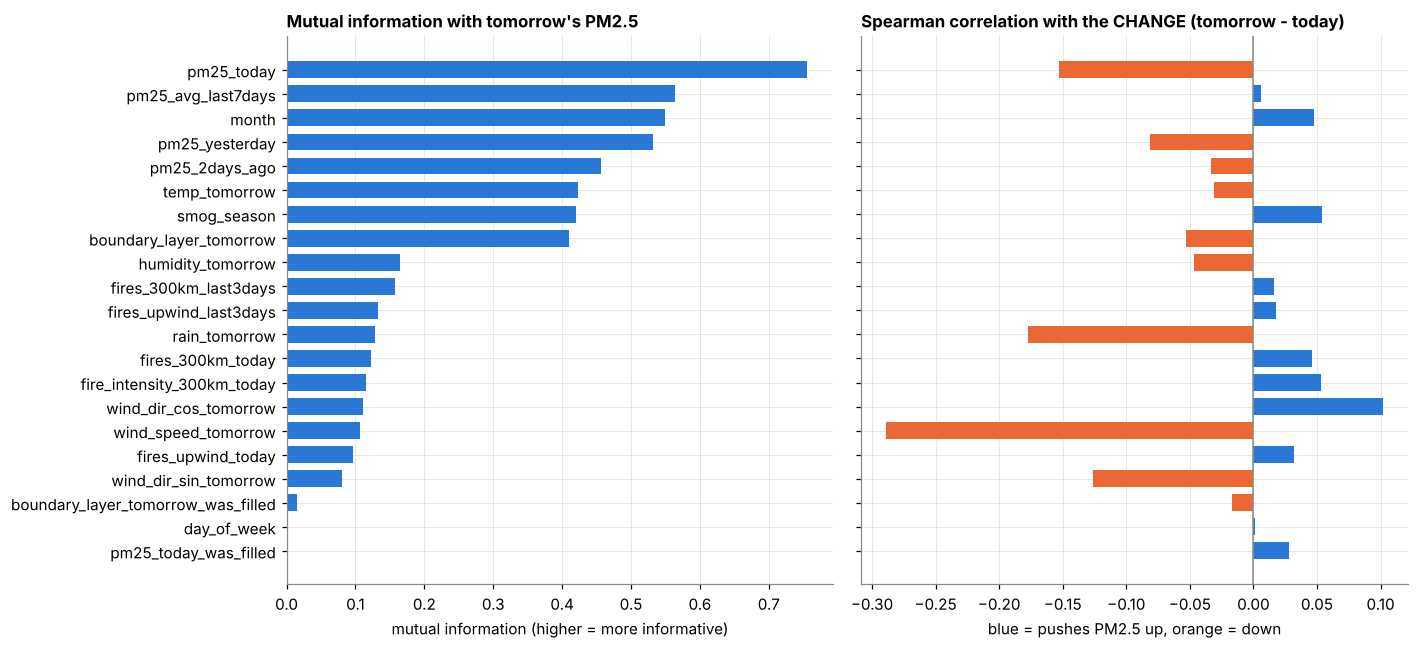

In [36]:
fig, axes = plt.subplots(1, 2, figsize=(13, 6), sharey=True)
order = scores.index[::-1]
axes[0].barh(order, scores.loc[order, "mutual_info_target"], color=BLUE, height=0.7)
axes[0].set(title="Mutual information with tomorrow's PM2.5", xlabel="mutual information (higher = more informative)")
colors = [BLUE if v >= 0 else ORANGE for v in scores.loc[order, "spearman_vs_change"]]
axes[1].barh(order, scores.loc[order, "spearman_vs_change"], color=colors, height=0.7)
axes[1].axvline(0, color=GREY, lw=1)
axes[1].set(title="Spearman correlation with the CHANGE (tomorrow - today)", xlabel="blue = pushes PM2.5 up, orange = down")
fig.tight_layout(); savefig(fig, "06_feature_scores")

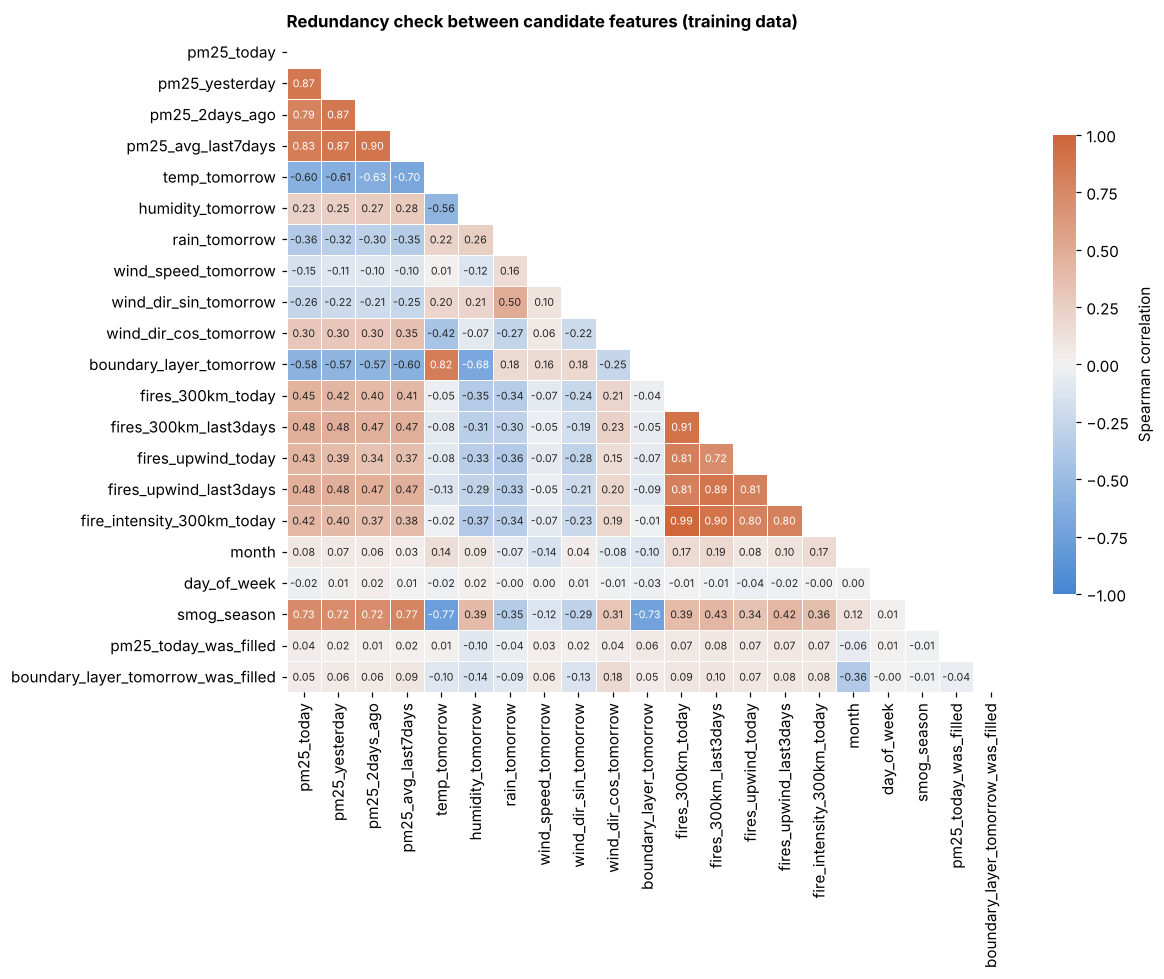

Highly redundant pairs (|r| > 0.85):
fire_intensity_300km_today  fires_300km_today       0.99
fires_300km_last3days       fires_300km_today       0.91
fire_intensity_300km_today  fires_300km_last3days   0.90
pm25_avg_last7days          pm25_2days_ago          0.90
fires_upwind_last3days      fires_300km_last3days   0.89
pm25_avg_last7days          pm25_yesterday          0.87
pm25_2days_ago              pm25_yesterday          0.87
pm25_yesterday              pm25_today              0.87


In [37]:
corr = train[CANDIDATES].corr(method="spearman")
fig, ax = plt.subplots(figsize=(11, 9))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, cmap=sns.diverging_palette(250, 25, s=80, l=55, as_cmap=True), center=0, vmin=-1, vmax=1,
            annot=True, fmt=".2f", annot_kws={"size": 7}, linewidths=0.5, linecolor="white",
            cbar_kws={"label": "Spearman correlation", "shrink": 0.7}, ax=ax)
ax.set_title("Redundancy check between candidate features (training data)")
ax.grid(False)
fig.tight_layout(); savefig(fig, "07_feature_redundancy")

pairs = corr.where(~mask).stack()
print("Highly redundant pairs (|r| > 0.85):")
print(pairs[pairs.abs() > 0.85].sort_values(ascending=False).round(2).to_string())

**Selection decision.** Combining the three views:

**What the scores show:**
- **Persistence dominates the level.** `pm25_today` has by far the highest mutual information (0.76), followed by the 7-day average and yesterday.
- The **season** features (`month`, `smog_season`), and `temp_tomorrow` and `boundary_layer_tomorrow` (which mostly track the season), come next.
- For the **change** from today, the picture is different. **Wind speed (−0.29), rain (−0.18) and wind direction** matter most, and `pm25_today` is negative (−0.15): very high days tend to fall back the next day. This is where the weather forecast earns its place.
- The fire features have moderate MI (0.10–0.16) over the whole year. Fires only matter in two short seasons, which is why we study them in Oct–Nov separately in Section 7.6.

| Decision | Features | Reason |
|---|---|---|
| **Keep: persistence** | `pm25_today`, `pm25_yesterday`, `pm25_avg_last7days` | The three most informative features. Today and yesterday are correlated (r = 0.87), but their *difference* tells the model whether pollution is rising or falling. |
| **Keep: tomorrow's weather** | `boundary_layer_tomorrow`, `temp_tomorrow`, `humidity_tomorrow`, `wind_speed_tomorrow`, `rain_tomorrow`, `wind_dir_sin_tomorrow`, `wind_dir_cos_tomorrow` | They explain the level (BLH, temperature) and the change (wind speed, rain, direction) |
| **Keep: fires (research question)** | `fires_upwind_last3days`, `fires_300km_last3days`, `fire_intensity_300km_today` | The 3-day sums have higher MI than the single-day counts. Upwind and all-direction fires are correlated (r = 0.89), but we keep **both on purpose** so that Phase 2 can test which definition helps more. |
| **Keep: calendar** | `month`, `smog_season` | High MI and cheap |
| **Drop: redundant** | `pm25_2days_ago` (r = 0.90 with the 7-day average), `fires_300km_today` (r = 0.99 with fire intensity), `fires_upwind_today` (weaker than its 3-day version) | Near-duplicates of kept features; they add noise, not information |
| **Drop: no signal** | `day_of_week` | MI = 0.00 and correlation ≈ 0. Lahore's smog is not a weekday or weekend effect. |
| **Not used as inputs (flags)** | `pm25_today_was_filled`, `boundary_layer_tomorrow_was_filled` | MI ≈ 0. Kept in the file so that we can check whether filled rows have larger errors. |

This gives **15 selected input features**. In Phase 2 we will confirm the choice with model-based importance (permutation importance) and an **ablation test**: the same model with and without the fire features.

In [38]:
SELECTED_FEATURES = ["pm25_today", "pm25_yesterday", "pm25_avg_last7days",
                     "boundary_layer_tomorrow", "temp_tomorrow", "humidity_tomorrow", "wind_speed_tomorrow", "rain_tomorrow",
                     "wind_dir_sin_tomorrow", "wind_dir_cos_tomorrow",
                     "fires_upwind_last3days", "fires_300km_last3days", "fire_intensity_300km_today",
                     "month", "smog_season"]
FIRE_FEATURES = ["fires_upwind_last3days", "fires_300km_last3days", "fire_intensity_300km_today"]
json.dump({"selected_features": SELECTED_FEATURES, "fire_features": FIRE_FEATURES,
           "targets": {"regression": "pm25_tomorrow", "multiclass": "aqi_category_tomorrow", "binary": "hazardous_tomorrow"},
           "hazardous_threshold_ug_m3": HAZARDOUS},
          open(OUT_DIR / "selected_features.json", "w"), indent=2)
print(f"{len(SELECTED_FEATURES)} features selected and saved to {OUT_DIR.name}/selected_features.json")

15 features selected and saved to processed/selected_features.json


# 7. Exploratory data analysis
The EDA answers five questions, each of which shapes the Phase-2 model:

1. **How bad is the smog, and when?** (7.1–7.3): the target's history, seasonality and distribution.
2. **How predictable is tomorrow from today?** (7.4): persistence, which gives the baseline to beat.
3. **When and where do crops burn?** (7.5): the fire seasons and Pakistan vs India.
4. **Do fires actually raise Lahore's PM2.5?** (7.6): the research question.
5. **What role does the weather play?** (7.7–7.8). Then the correlations, and the differences between train and test (7.9–7.10).

## 7.1 PM2.5 over time
Each dot is one day, coloured by its data source. The red line is the **Hazardous** threshold (225.5 µg/m³).

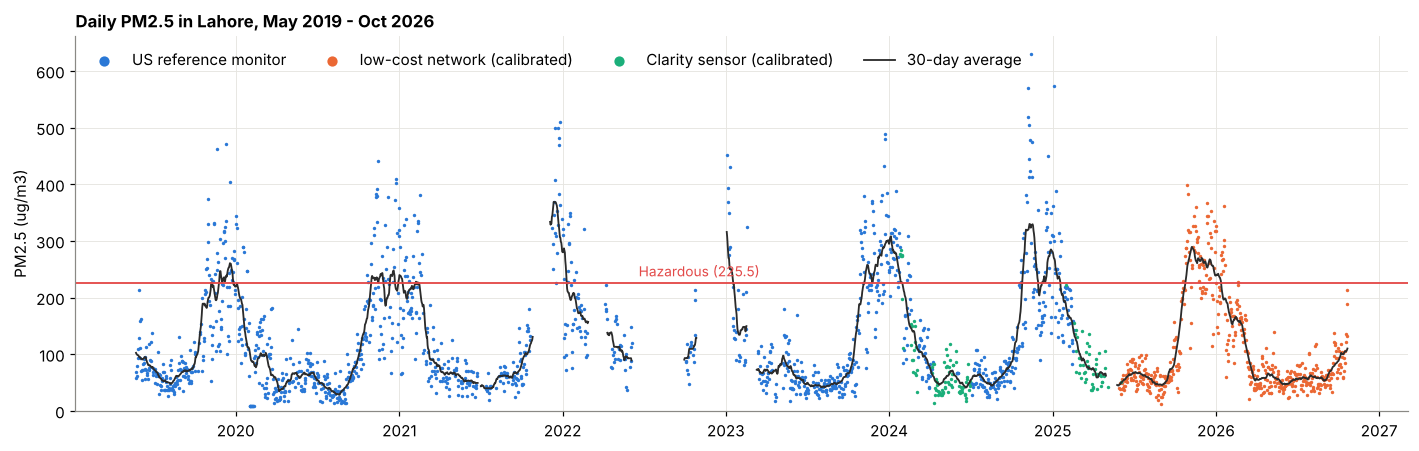

In [39]:
fig, ax = plt.subplots(figsize=(13, 4.2))
for src, col, lab in [("reference", BLUE, "US reference monitor"), ("lowcost_calibrated", ORANGE, "low-cost network (calibrated)"),
                      ("clarity_calibrated", AQUA, "Clarity sensor (calibrated)")]:
    s = daily.loc[daily.pm25_source == src, "pm25"]
    ax.scatter(s.index, s.values, s=5, color=col, label=lab, linewidths=0)
roll = daily["pm25"].rolling(30, min_periods=10, center=True).mean()
ax.plot(roll.index, roll.values, color="#2b2b2b", lw=1.2, label="30-day average")
ax.axhline(HAZARDOUS, color=RED, lw=1.2)
ax.text(pd.Timestamp("2022-06-20"), HAZARDOUS + 12, "Hazardous (225.5)", color=RED, fontsize=9)
ax.set(title="Daily PM2.5 in Lahore, May 2019 - Oct 2026", ylabel="PM2.5 (ug/m3)", ylim=(0, None))
ax.legend(loc="upper left", ncol=4, markerscale=3, bbox_to_anchor=(0, 1.0))
nice_dates(ax)
fig.tight_layout(); savefig(fig, "08_pm25_timeseries")

**Discussion:**
- The pattern repeats every year, like a heartbeat: **clean monsoon summers** (often under 50 µg/m³) and **severe winters**, with peaks in **November**.
- Peak days go well past 400 µg/m³, which is about **27 times** the WHO 24-hour guideline of 15 µg/m³.
- The calibrated low-cost series (orange, 2025–26) continues the reference series (blue) smoothly, with no visible jump. This is a visual confirmation that the calibration in Section 5.3 worked.

## 7.2 Seasonality: which months, and is it getting worse?

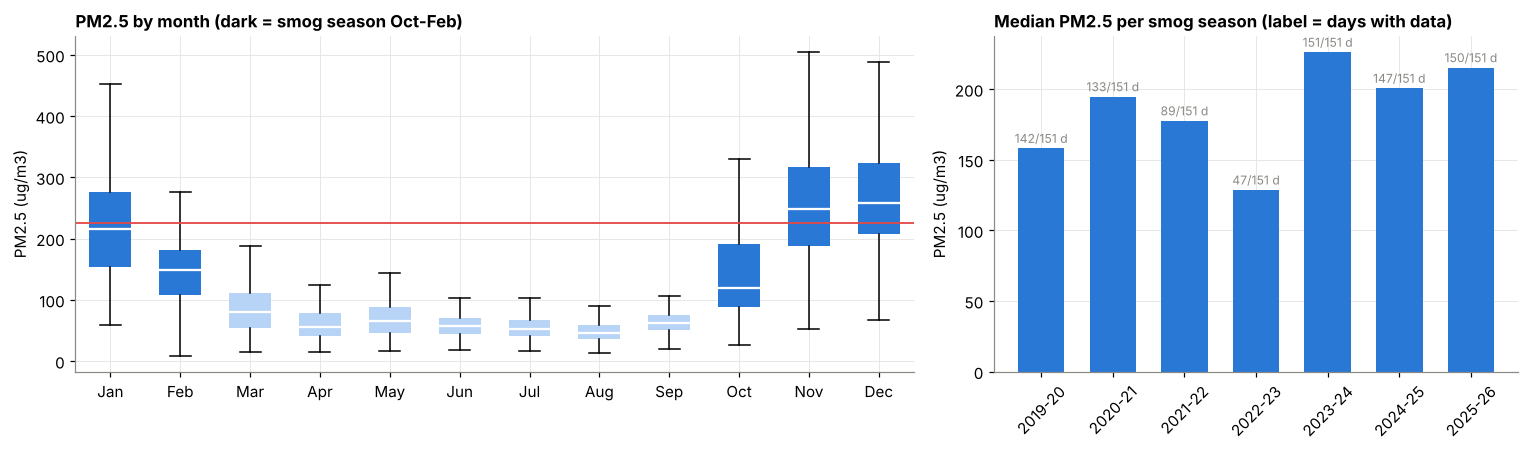

,median,hazardous_days,days_with_data,days
winter,,,,
2019-20,158.00,45,142,151
2020-21,195.00,50,133,151
2021-22,178.00,35,89,151
2022-23,128.00,9,47,151
2023-24,226.00,76,151,151
2024-25,201.00,55,147,151
2025-26,215.00,67,150,151


In [40]:
mon = daily.dropna(subset=["pm25"]).assign(month=lambda x: x.index.month)
month_names = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2), gridspec_kw={"width_ratios": [1.6, 1]})
data = [mon.loc[mon.month == m, "pm25"].values for m in range(1, 13)]
bp = axes[0].boxplot(data, patch_artist=True, widths=0.6, showfliers=False, medianprops={"color": "white", "lw": 1.5})
for patch, m in zip(bp["boxes"], range(1, 13)):
    patch.set(facecolor=BLUE if m in (10, 11, 12, 1, 2) else "#b7d3f6", linewidth=0)
axes[0].axhline(HAZARDOUS, color=RED, lw=1.2)
axes[0].set_xticks(range(1, 13), month_names)
axes[0].set(title="PM2.5 by month (dark = smog season Oct-Feb)", ylabel="PM2.5 (ug/m3)")

winters = []
for y in range(2019, 2026):
    w = daily.loc[f"{y}-10-01":f"{y + 1}-02-28", "pm25"]
    winters.append({"winter": f"{y}-{str(y + 1)[2:]}", "median": w.median(), "hazardous_days": int((w >= HAZARDOUS).sum()),
                    "days_with_data": int(w.notna().sum()), "days": len(w)})
winters = pd.DataFrame(winters).set_index("winter")
bars = axes[1].bar(winters.index, winters["median"], color=BLUE, width=0.65)
for b, (_, r) in zip(bars, winters.iterrows()):
    axes[1].text(b.get_x() + b.get_width() / 2, b.get_height() + 4, f"{int(r.days_with_data)}/{int(r.days)} d", ha="center", fontsize=8, color=GREY)
axes[1].set(title="Median PM2.5 per smog season (label = days with data)", ylabel="PM2.5 (ug/m3)")
axes[1].tick_params(axis="x", rotation=45)
fig.tight_layout(); savefig(fig, "09_seasonality")
display(winters.round(0))

**Discussion:**
- **November and December are the worst months**: medians of about **250–260 µg/m³**, above the Hazardous line, with January close behind (about 216 µg/m³). Pollution jumps in November, together with the rice-stubble burning season, but **December is just as bad even though the fires are over by then**. Cold, calm, foggy weather traps the pollution. Fires are therefore **not the only driver**, and the weather matters at least as much.
- **August (monsoon rain) is the cleanest month**, with a median below 50 µg/m³.
- The **three most recent winters (2023–24 to 2025–26) have the highest medians (201–226 µg/m³)**, and 55–76 hazardous days each. The low 2022–23 value rests on only 47 days of data, so it is not reliable. The problem is not going away, which shows how relevant this project is.

## 7.3 Distribution of the target and AQI categories

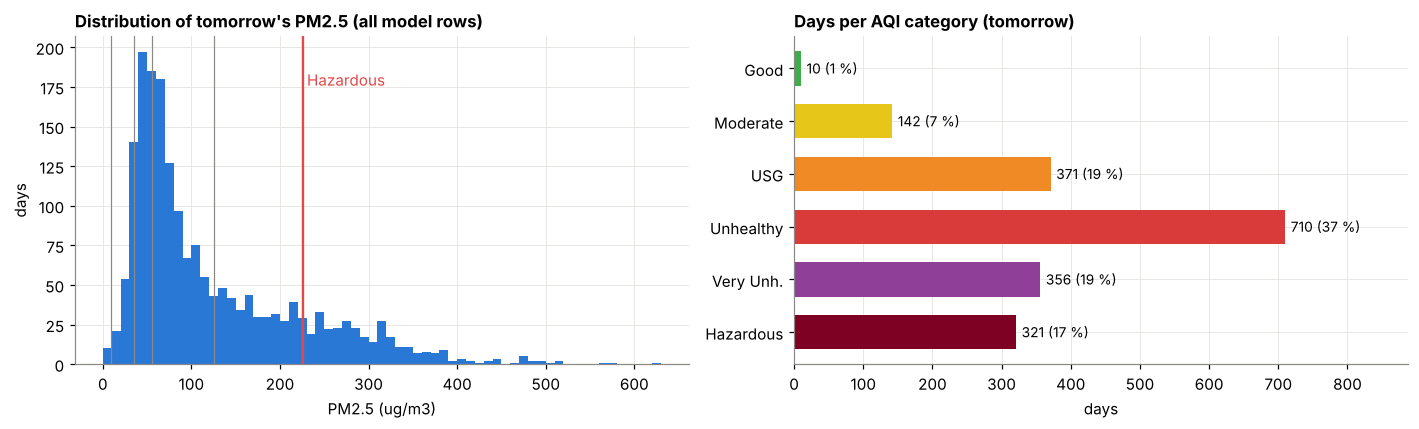

Mean 125, median 84, max 630 ug/m3 | skewness 1.39


In [41]:
cats = model_df["aqi_category_tomorrow"].value_counts().reindex(AQI_LABELS).fillna(0).astype(int)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
x = model_df["pm25_tomorrow"]
edges = np.arange(0, x.max() + 10, 10)
axes[0].hist(x, bins=edges, color=BLUE)
for b, lab in zip(AQI_BINS[1:-1], AQI_SHORT[1:]):
    axes[0].axvline(b, color=GREY, lw=0.8)
axes[0].axvline(HAZARDOUS, color=RED, lw=1.5)
axes[0].text(HAZARDOUS + 5, axes[0].get_ylim()[1] * 0.85, "Hazardous", color=RED)
axes[0].set(title="Distribution of tomorrow's PM2.5 (all model rows)", xlabel="PM2.5 (ug/m3)", ylabel="days")

axes[1].barh(AQI_SHORT[::-1], cats.values[::-1], color=AQI_COLORS[::-1], height=0.65)
for i, v in enumerate(cats.values[::-1]):
    axes[1].text(v + 8, i, f"{v} ({100 * v / cats.sum():.0f} %)", va="center", fontsize=9)
axes[1].set(title="Days per AQI category (tomorrow)", xlabel="days", xlim=(0, cats.max() * 1.25))
fig.tight_layout(); savefig(fig, "10_target_distribution")
print(f"Mean {x.mean():.0f}, median {x.median():.0f}, max {x.max():.0f} ug/m3 | skewness {x.skew():.2f}")

**Discussion:**
- **Imbalanced classes.** Almost no day is *Good* (Lahore essentially never meets the 9 µg/m³ standard), and *Unhealthy* is the most common category.
- **Hazardous days are a minority** (17 % of all evenings, but 37–45 % of test-winter evenings). For the binary warning we must therefore report **recall, precision and F1**, not accuracy: a model that always says "not hazardous" would be about 84 % accurate and completely useless.
- For the multi-class task we may merge *Good* into *Moderate*, because there are too few *Good* days to learn from.

## 7.4 Persistence: how much does today tell us about tomorrow?

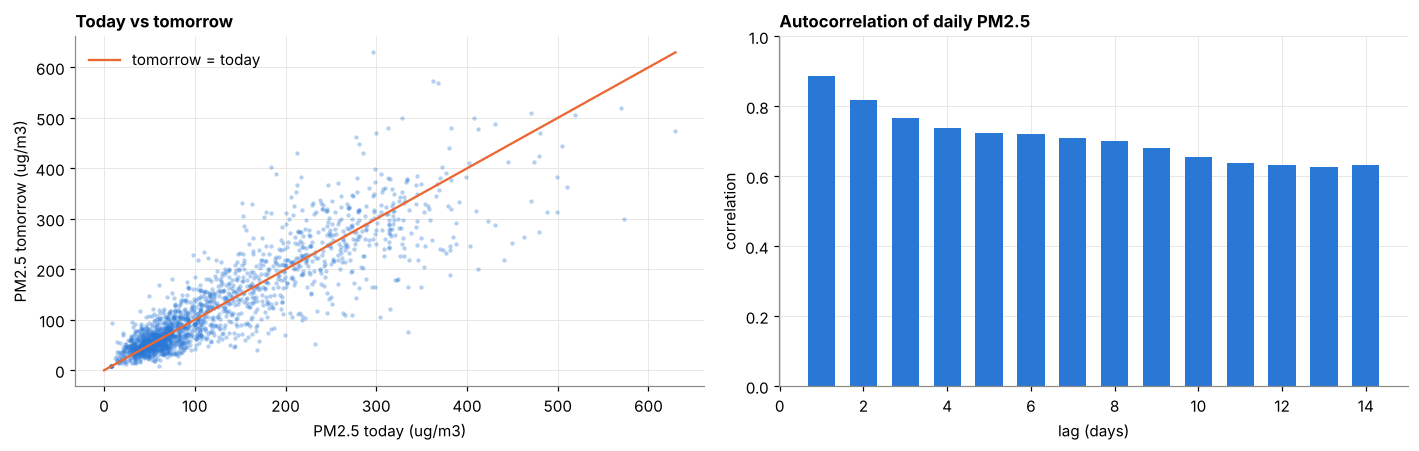

Persistence baseline ('tomorrow = today') - the score every Phase-2 model must beat:


,rows,MAE (ug/m3),RMSE (ug/m3),hazardous recall %,hazardous precision %
extra,372.00,15.60,20.30,0.00,0.00
test_winter_2024_25,147.00,52.50,78.30,80.00,80.00
test_winter_2025_26,150.00,33.80,44.00,85.10,85.10
train,"1,241.00",31.20,47.70,77.40,77.80


In [42]:
lag_corr = [daily["pm25"].autocorr(lag=k) for k in range(1, 15)]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
axes[0].scatter(model_df["pm25_today"], model_df["pm25_tomorrow"], s=8, alpha=0.35, color=BLUE, linewidths=0)
lim = model_df[["pm25_today", "pm25_tomorrow"]].max().max()
axes[0].plot([0, lim], [0, lim], color=ORANGE, lw=1.5, label="tomorrow = today")
axes[0].set(title="Today vs tomorrow", xlabel="PM2.5 today (ug/m3)", ylabel="PM2.5 tomorrow (ug/m3)")
axes[0].legend(loc="upper left")
axes[1].bar(range(1, 15), lag_corr, color=BLUE, width=0.65)
axes[1].set(title="Autocorrelation of daily PM2.5", xlabel="lag (days)", ylabel="correlation", ylim=(0, 1))
fig.tight_layout(); savefig(fig, "11_persistence")

def persistence_scores(df):
    err = df["pm25_tomorrow"] - df["pm25_today"]
    hz_true, hz_pred = df["hazardous_tomorrow"] == 1, df["pm25_today"] >= HAZARDOUS
    return pd.Series({"rows": len(df), "MAE (ug/m3)": err.abs().mean(), "RMSE (ug/m3)": np.sqrt((err ** 2).mean()),
                      "hazardous recall %": 100 * (hz_true & hz_pred).sum() / max(hz_true.sum(), 1),
                      "hazardous precision %": 100 * (hz_true & hz_pred).sum() / max(hz_pred.sum(), 1)})
baseline = pd.DataFrame({s: persistence_scores(g) for s, g in model_df.groupby("split")}).T.round(1)
print("Persistence baseline ('tomorrow = today') - the score every Phase-2 model must beat:")
baseline

**Discussion:**
- PM2.5 is **highly persistent**: the lag-1 autocorrelation is 0.89, and it decays slowly (still above 0.6 after two weeks). The simplest forecast, *"tomorrow = today"*, is therefore already strong. This **persistence baseline** is the score every Phase-2 model must beat.
- On the test winters it makes average errors of **52.5 µg/m³ (2024–25)** and **33.8 µg/m³ (2025–26)**. As a hazardous-air warning it already catches **80–85 %** of hazardous days, with similar precision.
- Its weakness is that it **always reacts one day late**: it misses the first day of every smog episode, and it raises false alarms on the day the air clears. Those turning points are exactly where tomorrow's weather and the fire features should help.
- For this reason, in Phase 2 we will also try predicting the **change** (tomorrow − today) rather than the raw level.

## 7.5 Crop burning: when, where, and on which side of the border?

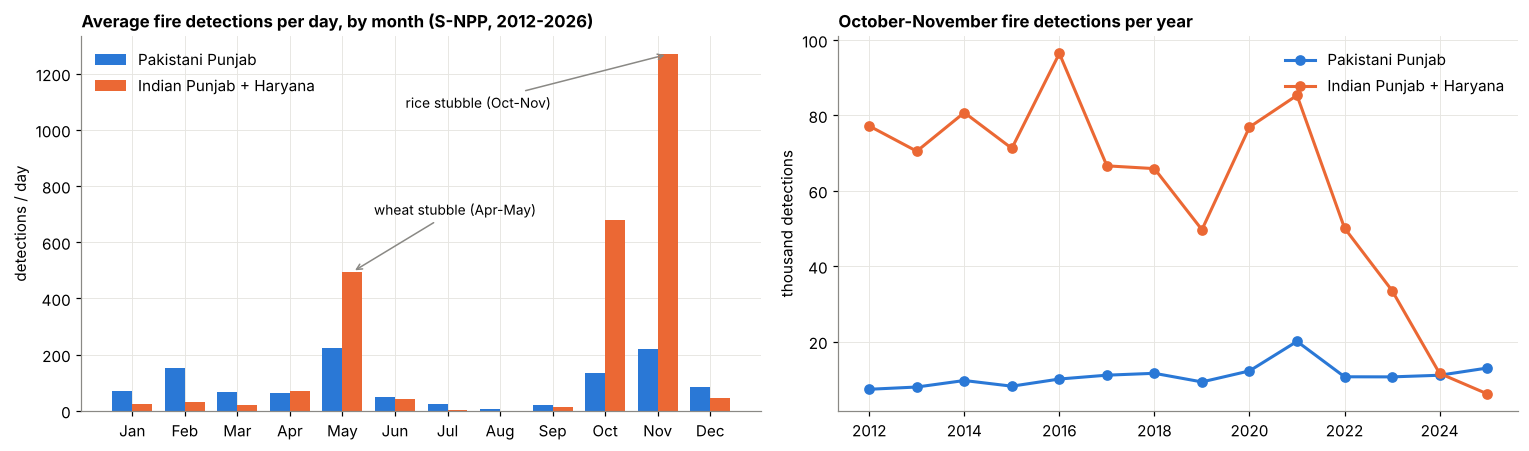

date,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
pakistan_punjab,7.30,7.90,9.70,8.20,10.10,11.10,11.60,9.30,12.20,20.00,10.70,10.60,11.10,13.00
india_punjab_haryana,77.20,70.50,80.80,71.30,96.40,66.60,65.90,49.70,76.90,85.30,50.10,33.50,11.60,6.10


In [43]:
clim = regional.groupby(regional.index.month).mean()
oct_nov = regional[regional.index.month.isin([10, 11])].groupby(lambda d: d.year).sum()
oct_nov = oct_nov.loc[2012:2025]
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
w = 0.38
xm = np.arange(1, 13)
axes[0].bar(xm - w / 2, clim["pakistan_punjab"], width=w, color=BLUE, label="Pakistani Punjab")
axes[0].bar(xm + w / 2, clim["india_punjab_haryana"], width=w, color=ORANGE, label="Indian Punjab + Haryana")
axes[0].set_xticks(xm, month_names)
axes[0].set(title="Average fire detections per day, by month (S-NPP, 2012-2026)", ylabel="detections / day")
axes[0].legend(loc="upper left")
axes[0].annotate("wheat stubble (Apr-May)", xy=(5 + w / 2, clim.loc[5, "india_punjab_haryana"]), xytext=(5.6, clim.max().max() * 0.55),
                 arrowprops={"arrowstyle": "->", "color": GREY}, fontsize=9)
axes[0].annotate("rice stubble (Oct-Nov)", xy=(11 + w / 2, clim.loc[11, "india_punjab_haryana"]), xytext=(6.2, clim.max().max() * 0.85),
                 arrowprops={"arrowstyle": "->", "color": GREY}, fontsize=9)
yrs = oct_nov.index
axes[1].plot(yrs, oct_nov["pakistan_punjab"] / 1e3, color=BLUE, marker="o", lw=2, label="Pakistani Punjab")
axes[1].plot(yrs, oct_nov["india_punjab_haryana"] / 1e3, color=ORANGE, marker="o", lw=2, label="Indian Punjab + Haryana")
axes[1].set(title="October-November fire detections per year", ylabel="thousand detections")
axes[1].legend(loc="upper right")
fig.tight_layout(); savefig(fig, "12_fire_seasons")
display((oct_nov / 1e3).round(1).T)

**Discussion:**
- There are **two burning seasons**: **April–May**, when wheat stubble is burnt in the hot dry season and PM2.5 stays moderate, and **October–November**, when rice stubble is burnt. The second season coincides with the start of the smog season.
- **Trend:** Oct–Nov detections in **Indian Punjab + Haryana fell dramatically after 2021**, from about 85 thousand to 6 thousand in 2025. India has pushed residue-management machinery and enforcement, and part of the burning may also have moved to times when the satellites do not pass over. **Pakistani Punjab stayed at 10–13 thousand** (peaking at 20 thousand in 2021), so **in 2024 the two sides were level, and in 2025 Pakistan had twice as many detections as India**.
- This matters for policy: **a growing share of the smoke near Lahore now comes from Pakistan's own fields**. The maps below show this for the area around Lahore.

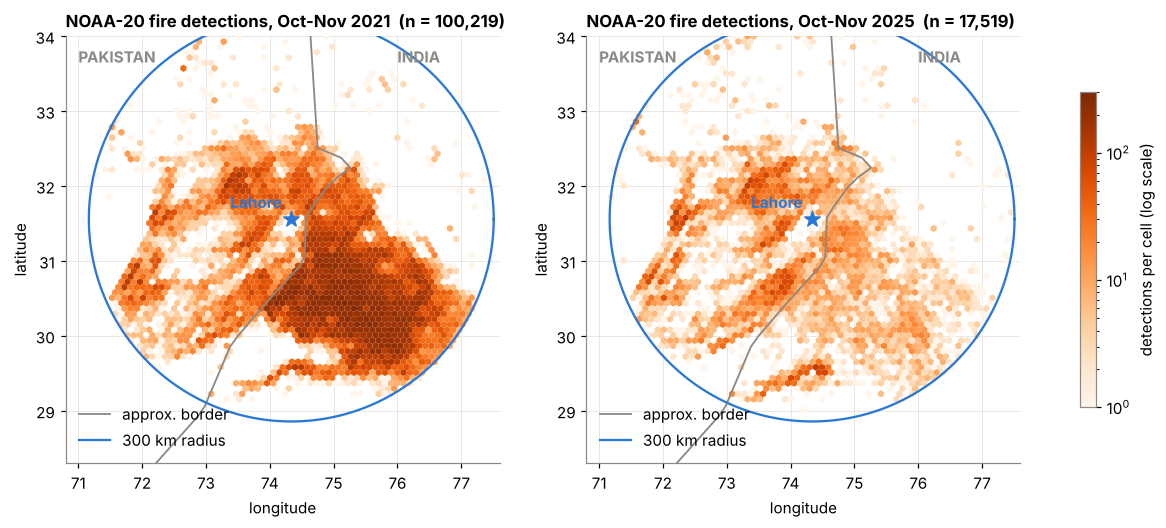

NOAA-20 detections within 300 km of Lahore in October-November:


Oct-Nov of,2018,2019,2020,2021,2022,2023,2024,2025
country,,,,,,,,
India,66929,48012,77908,81218,51955,35454,13110,6023
Pakistan,11277,8894,11260,19001,10183,9640,11472,11496
Pakistan share %,14,16,13,19,16,21,47,66


In [44]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6.2))
th = np.linspace(0, 2 * np.pi, 200)
for ax, year in zip(axes, [2021, 2025]):
    season = n20[(n20.date >= f"{year}-10-01") & (n20.date <= f"{year}-11-30")]
    hb = ax.hexbin(season.longitude, season.latitude, gridsize=70, bins="log", cmap="Oranges", mincnt=1, linewidths=0,
                   vmin=1, vmax=300, extent=(70.8, 77.6, 28.3, 34.0))
    ax.plot(np.interp(np.linspace(28, 34.5, 50), [b[0] for b in BORDER], [b[1] for b in BORDER]), np.linspace(28, 34.5, 50),
            color=GREY, lw=1.2, label="approx. border")
    ax.plot(LAHORE_LON + (FIRE_RADIUS_KM / 111) / np.cos(np.radians(LAHORE_LAT)) * np.cos(th),
            LAHORE_LAT + (FIRE_RADIUS_KM / 111) * np.sin(th), color=BLUE, lw=1.5, label="300 km radius")
    ax.scatter([LAHORE_LON], [LAHORE_LAT], s=110, color=BLUE, zorder=5, marker="*")
    ax.text(LAHORE_LON - 0.15, LAHORE_LAT + 0.15, "Lahore", color=BLUE, fontweight="bold", ha="right")
    ax.text(71.0, 33.65, "PAKISTAN", color=GREY, fontsize=10, fontweight="bold")
    ax.text(76.0, 33.65, "INDIA", color=GREY, fontsize=10, fontweight="bold")
    ax.set(title=f"NOAA-20 fire detections, Oct-Nov {year}  (n = {len(season):,})", xlabel="longitude", ylabel="latitude",
           xlim=(70.8, 77.6), ylim=(28.3, 34.0))
    ax.set_aspect(1 / np.cos(np.radians(LAHORE_LAT)))
    ax.legend(loc="lower left")
fig.colorbar(hb, ax=axes, shrink=0.6, label="detections per cell (log scale)")
savefig(fig, "13_fire_maps")

near = n20[n20.date.dt.month.isin([10, 11]) & (n20.date.dt.year <= 2025)]   # complete seasons only
share = near.groupby([near.date.dt.year, "country"]).size().unstack().fillna(0)
share["Pakistan share %"] = 100 * share["Pakistan"] / share[["India", "Pakistan"]].sum(axis=1)
share.index.name = "Oct-Nov of"
print("NOAA-20 detections within 300 km of Lahore in October-November:")
share.round().astype(int).T

**Discussion:**
- **2021:** the fires within 300 km form a huge, dense belt in **Indian Punjab** (Amritsar, Ferozepur, Bathinda), with a second belt on the Pakistani side (Sheikhupura, Kasur, Okara, Gujranwala). Lahore sits **between** the two.
- **2025:** the Indian belt has almost disappeared, while the Pakistani belt remains. The table shows the shift: **Pakistan's share of the fires near Lahore rose from about 13–21 % (2018–2023) to 47 % in 2024 and 66 % in 2025.**
- **For the model:** fires surround Lahore on several sides, and their geography changes from year to year. So the **wind direction**, which decides which fires are upwind, and a fixed radius rather than a fixed country, are the right way to build fire features.

## 7.6 Do fires raise Lahore's PM2.5? (research question)
A naive correlation would be misleading: fires happen in Oct–Nov, *and* the weather turns stagnant in Oct–Nov, so the two could be correlated only through the season. We therefore look **only within the burning season (Oct–Nov)** and ask three questions:

1. Is tomorrow's PM2.5 higher after days with more fires?
2. Do **upwind** fires matter more than fires in any direction?
3. Do fires predict the **change** in PM2.5, i.e. after controlling for today's level?

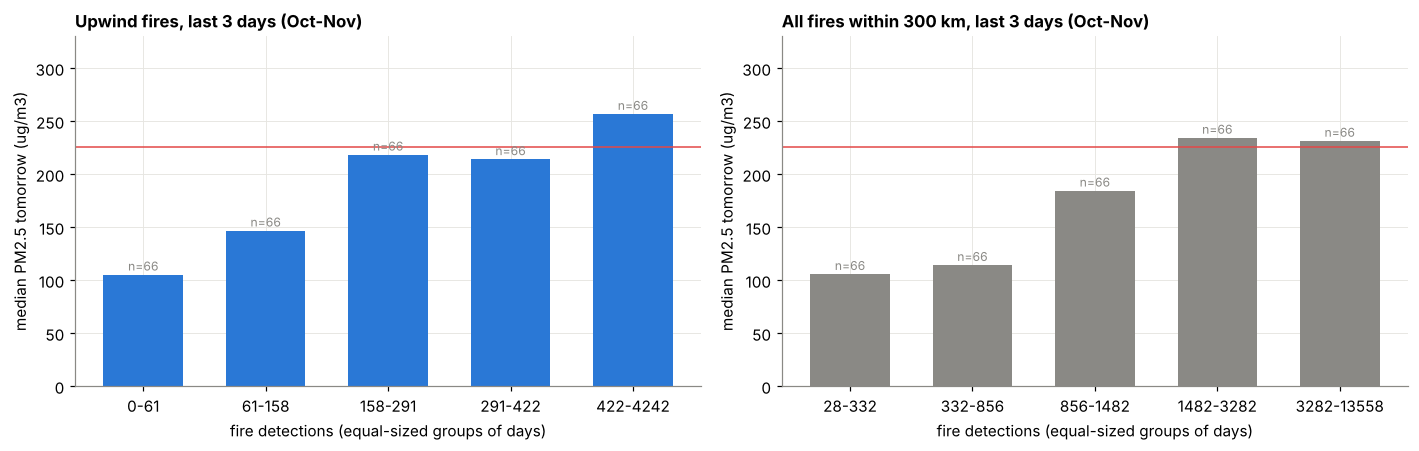

Oct-Nov rows: 330 | Spearman correlations:


,corr. with PM2.5 tomorrow,corr. with change (tomorrow - today)
feature,,
fires_upwind_last3days,0.47,0.09
fires_300km_last3days,0.47,0.10
fires_upwind_today,0.37,0.11
fires_300km_today,0.39,0.13
fire_intensity_300km_today,0.38,0.13


In [45]:
burn = model_df[model_df.month.isin([10, 11])].copy()
burn["change"] = burn["pm25_tomorrow"] - burn["pm25_today"]
def quantile_bins(s, q):
    "Split a variable into q equal-sized groups and label each group with its value range."
    b = pd.qcut(s, q, duplicates="drop")
    return b.cat.rename_categories([f"{max(iv.left, 0):.0f}-{iv.right:.0f}" for iv in b.cat.categories])

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for ax, col, title in [(axes[0], "fires_upwind_last3days", "Upwind fires, last 3 days"),
                       (axes[1], "fires_300km_last3days", "All fires within 300 km, last 3 days")]:
    b = quantile_bins(burn[col], 5)                     # five equal-sized groups of days
    g = burn.groupby(b, observed=False)["pm25_tomorrow"].agg(["median", "size"])
    bars = ax.bar(g.index.astype(str), g["median"], color=BLUE if "upwind" in col else GREY, width=0.65)
    for bar, n in zip(bars, g["size"]):
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 4, f"n={n}", ha="center", fontsize=8, color=GREY)
    ax.axhline(HAZARDOUS, color=RED, lw=1)
    ax.set(title=title + " (Oct-Nov)", xlabel="fire detections (equal-sized groups of days)", ylabel="median PM2.5 tomorrow (ug/m3)", ylim=(0, 330))
fig.tight_layout(); savefig(fig, "14_fires_vs_pm25")

rows = []
for col in ["fires_upwind_last3days", "fires_300km_last3days", "fires_upwind_today", "fires_300km_today", "fire_intensity_300km_today"]:
    rows.append({"feature": col, "corr. with PM2.5 tomorrow": burn[col].corr(burn["pm25_tomorrow"], method="spearman"),
                 "corr. with change (tomorrow - today)": burn[col].corr(burn["change"], method="spearman")})
fire_corr = pd.DataFrame(rows).set_index("feature").round(3)
print(f"Oct-Nov rows: {len(burn)} | Spearman correlations:")
fire_corr

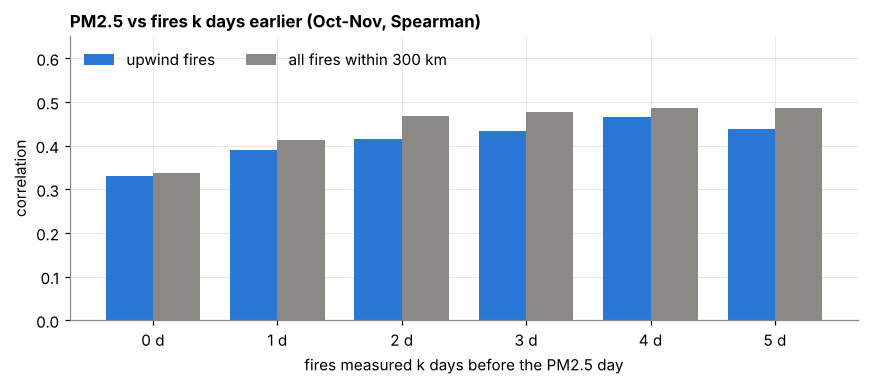

In [46]:
oct_nov_daily = daily[daily.index.month.isin([10, 11])]
lags = range(0, 6)
lag_up  = [oct_nov_daily["pm25"].corr(daily["fires_upwind_300km"].shift(k).reindex(oct_nov_daily.index), method="spearman") for k in lags]
lag_all = [oct_nov_daily["pm25"].corr(daily["fires_300km"].shift(k).reindex(oct_nov_daily.index), method="spearman") for k in lags]
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.bar(np.array(lags) - 0.19, lag_up, width=0.38, color=BLUE, label="upwind fires")
ax.bar(np.array(lags) + 0.19, lag_all, width=0.38, color=GREY, label="all fires within 300 km")
ax.set_xticks(list(lags), [f"{k} d" for k in lags])
ax.set(title="PM2.5 vs fires k days earlier (Oct-Nov, Spearman)", xlabel="fires measured k days before the PM2.5 day", ylabel="correlation")
ax.set_ylim(0, 0.65)
ax.legend(loc="upper left", ncol=2)
fig.tight_layout(); savefig(fig, "15_fire_lag")

**Discussion (research question):**
- **Within the burning season, more fires go with dirtier air.** We split the Oct–Nov days into five equal groups by fire count. Median PM2.5 tomorrow rises from group to group, from about 100 µg/m³ in the lowest group to around the hazardous line in the highest. Each fire feature has a Spearman correlation of about **0.4–0.5** with tomorrow's PM2.5.
- **Upwind vs all fires.** The two charts look similar, and the rank correlations are identical (0.47 each), so **"upwind" does not add much over "all fires within 300 km" at this daily resolution**. The daily-mean wind direction is a rough guide to where smoke really travels, because the wind turns during the day and smoke can drift for days. This is why we keep both versions and let Phase 2 decide.
- **The change signal is weak but positive** (+0.09 to +0.13). Fires add a little information beyond today's PM2.5 level.
- **Be careful with the lag chart.** The correlation is already 0.33 for same-day fires and keeps rising up to 4–5 days back. Real smoke transport takes 1–2 days, so the continued rise is mostly a **seasonal-timing effect**: fires peak in early November, and PM2.5 keeps climbing into December, partly because of the weather. Correlation alone therefore **overstates** the fire effect.
- **Conclusion for the research question:** the EDA supports a link but cannot prove it. The fair test is the Phase-2 **ablation**: does a model *with* the fire features beat the same model *without* them on the held-out winters?

## 7.7 Weather: the other half of the story
We look at the **smog season (Oct–Feb)** only, so that the season itself does not drive the comparison.

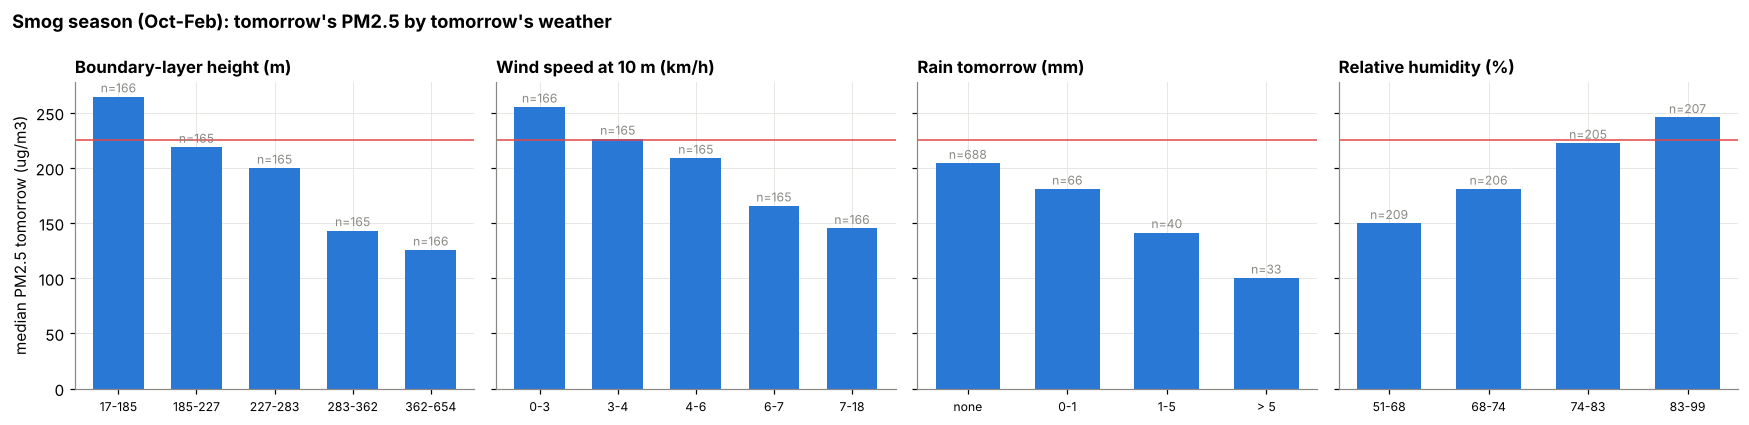

Spearman correlation with PM2.5 tomorrow (smog season):
boundary_layer_tomorrow   -0.54
wind_speed_tomorrow       -0.40
rain_tomorrow             -0.19
humidity_tomorrow          0.33
temp_tomorrow             -0.33


In [47]:
sm = model_df[model_df.smog_season == 1]

panels = [("boundary_layer_tomorrow", 5, "Boundary-layer height (m)"),
          ("wind_speed_tomorrow", 5, "Wind speed at 10 m (km/h)"),
          ("rain_tomorrow", None, "Rain tomorrow (mm)"),
          ("humidity_tomorrow", 4, "Relative humidity (%)")]
fig, axes = plt.subplots(1, 4, figsize=(16, 3.9), sharey=True)
for ax, (col, q, title) in zip(axes, panels):
    b = quantile_bins(sm[col], q) if q else pd.cut(sm[col], [-0.1, 0, 1, 5, 500], labels=["none", "0-1", "1-5", "> 5"])
    g = sm.groupby(b, observed=False)["pm25_tomorrow"].agg(["median", "size"])
    bars = ax.bar(g.index.astype(str), g["median"], color=BLUE, width=0.65)
    for bar, n in zip(bars, g["size"]):
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 4, f"n={n}", ha="center", fontsize=8, color=GREY)
    ax.axhline(HAZARDOUS, color=RED, lw=1)
    ax.set(title=title, xlabel="")
    ax.tick_params(axis="x", labelsize=8)
axes[0].set_ylabel("median PM2.5 tomorrow (ug/m3)")
fig.suptitle("Smog season (Oct-Feb): tomorrow's PM2.5 by tomorrow's weather", x=0.01, ha="left", fontweight="bold")
fig.tight_layout(); savefig(fig, "16_weather_vs_pm25")
weather_corr = sm[["boundary_layer_tomorrow", "wind_speed_tomorrow", "rain_tomorrow", "humidity_tomorrow", "temp_tomorrow"]] \
    .corrwith(sm["pm25_tomorrow"], method="spearman").round(2)
print("Spearman correlation with PM2.5 tomorrow (smog season):"); print(weather_corr.to_string())

**Discussion:**
- **Boundary-layer height is the strongest weather driver** (Spearman −0.54). Bars are equal-sized groups of days. In the shallowest fifth of winter days, pollution is trapped and the median PM2.5 is about **twice** that of the deepest fifth.
- **Wind ventilates the city** (−0.40): the calmest fifth of days are the worst, and the windiest are the cleanest.
- **Rain washes the air** (wet deposition). Rainy days, though rare in winter, are clearly cleaner.
- **Humid days are dirtier** (+0.33). This is a sign of fog and stagnant winter air, and also of particles growing by absorbing water.
- These relationships are **monotone and strong**, so a weather forecast for tomorrow should markedly improve on the persistence baseline.

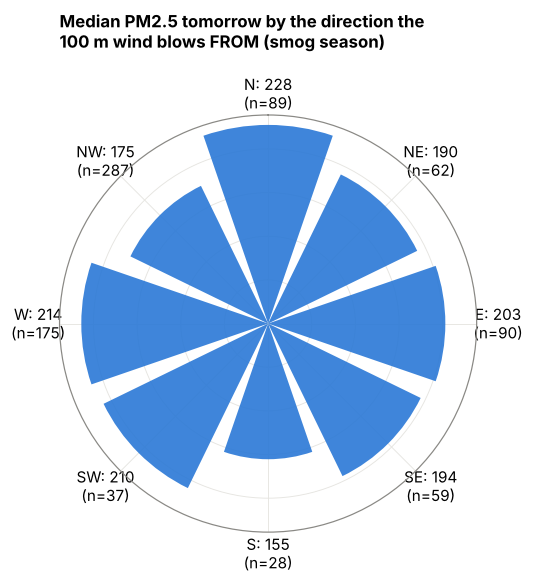

,N,NE,E,SE,S,SW,W,NW
median,228.00,190.00,203.00,194.00,155.00,210.00,214.00,175.00
size,89.00,62.00,90.00,59.00,28.00,37.00,175.00,287.00


In [48]:
sectors = ["N", "NE", "E", "SE", "S", "SW", "W", "NW"]
sec = ((sm["wind_dir_tomorrow"] + 22.5) % 360 // 45).astype(int)
by_sector = sm.groupby(sec)["pm25_tomorrow"].agg(["median", "size"]).reindex(range(8))
fig = plt.figure(figsize=(6, 5.4))
ax = fig.add_subplot(projection="polar")
ax.set_theta_zero_location("N"); ax.set_theta_direction(-1)
ax.bar(np.radians(np.arange(8) * 45), by_sector["median"], width=np.radians(38), color=BLUE, alpha=0.9)
ax.set_xticks(np.radians(np.arange(8) * 45),
              [f"{s}: {m:.0f}\n(n={int(n)})" for s, m, n in zip(sectors, by_sector["median"], by_sector["size"].fillna(0))])
ax.set_yticklabels([])                                   # the median value is written next to each direction
ax.set_title("Median PM2.5 tomorrow by the direction the\n100 m wind blows FROM (smog season)", pad=18)
fig.tight_layout(); savefig(fig, "17_wind_direction")
display(by_sector.set_axis(sectors).round(0).T)

**Discussion:**
- In winter the 100 m wind most often blows **from the north-west and west** (about half of all days).
- Median PM2.5 differs by up to about 70 µg/m³ between sectors. **Northerly** winds (median 228) and **westerly** winds (214) are the dirtiest. **North-westerly** winds (175), the most common sector and often linked to passing weather systems, and **southerly** winds (155, few days) are the cleanest.
- Easterly winds from the Indian fire belt are *not* the worst. This is consistent with the fire maps: much of the burning is to the west and north of Lahore, on the Pakistani side.
- **Direction carries information, but much less than wind speed or boundary-layer height.** We keep it as `wind_dir_sin/cos_tomorrow`, and it is also built into the upwind-fire features.

## 7.8 Correlation overview of the selected features

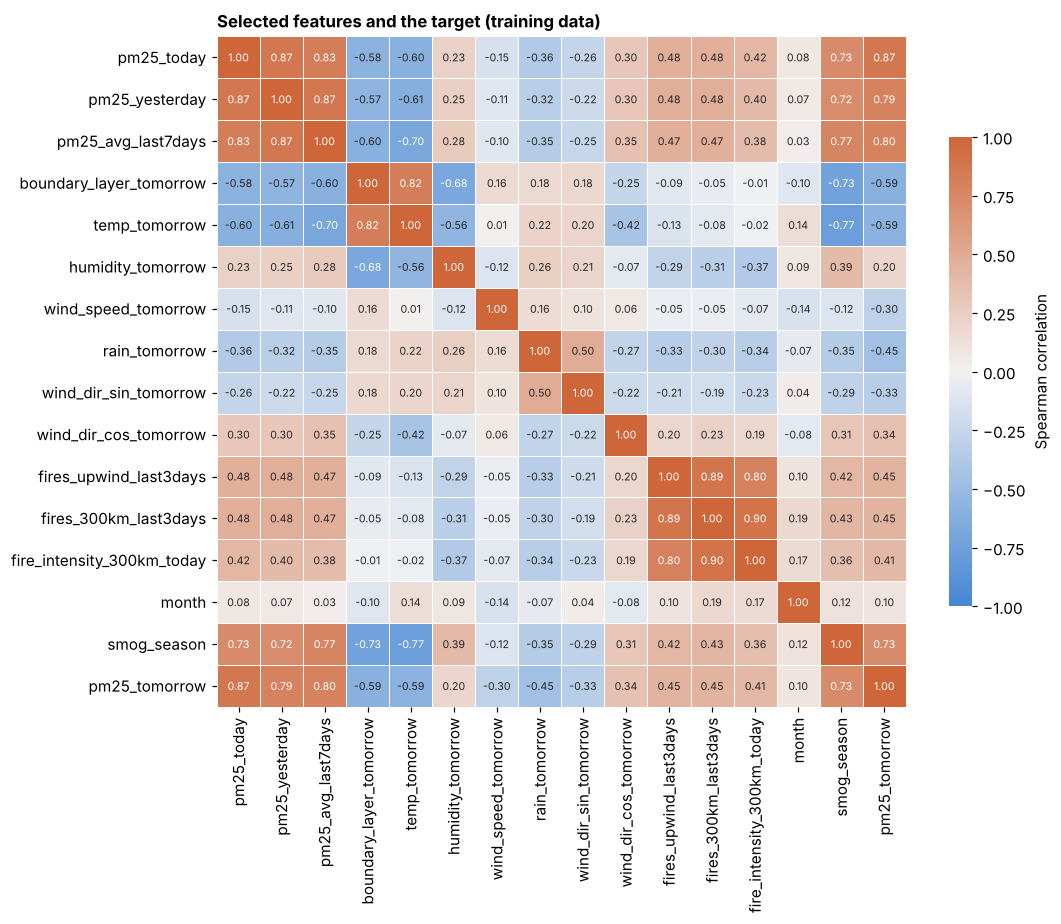

In [49]:
cols = SELECTED_FEATURES + ["pm25_tomorrow"]
c = model_df.loc[model_df.split == "train", cols].corr(method="spearman")
fig, ax = plt.subplots(figsize=(10, 8.5))
sns.heatmap(c, cmap=sns.diverging_palette(250, 25, s=80, l=55, as_cmap=True), center=0, vmin=-1, vmax=1,
            annot=True, fmt=".2f", annot_kws={"size": 7}, linewidths=0.5, linecolor="white",
            cbar_kws={"label": "Spearman correlation", "shrink": 0.7}, ax=ax)
ax.set_title("Selected features and the target (training data)")
ax.grid(False)
fig.tight_layout(); savefig(fig, "18_correlation_selected")

**Discussion:**
- The bottom row shows how each feature relates to the target. The **PM2.5 lags** are strongly positive. **Boundary-layer height, temperature and wind speed are negative**: warmer, windier days with deeper mixing are cleaner. **Humidity and the fire features are positive.**
- The weather features are correlated with **each other** (cold ↔ shallow boundary layer ↔ humid). Linear models would struggle with this; tree ensembles handle it well, but it means individual importances must be interpreted with care.

## 7.9 Day-of-week effect
Does traffic during the working week show up in PM2.5?

In [50]:
dow = model_df.groupby("day_of_week").agg(median_pm25_tomorrow=("pm25_tomorrow", "median"),
                                          median_change=("pm25_tomorrow", lambda s: (s - model_df.loc[s.index, "pm25_today"]).median()),
                                          evenings=("pm25_tomorrow", "size"))
dow.index = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
dow.round(1)

,median_pm25_tomorrow,median_change,evenings
Mon,87.10,0.50,273
Tue,84.90,5.50,272
Wed,83.70,-0.20,275
Thu,77.90,0.30,278
Fri,85.80,4.20,266
Sat,81.50,0.90,269
Sun,84.10,2.70,277


**Discussion:** the differences between weekdays are small compared with the day-to-day swings, and the typical change from one day to the next is close to zero for every weekday. Meteorology and burning dominate traffic timing, which is consistent with dropping `day_of_week` in Section 6.3.

## 7.10 Train vs test: are the test winters different?
A model can only be trusted if the test data looks like something it has learned from. We compare the target across the splits.

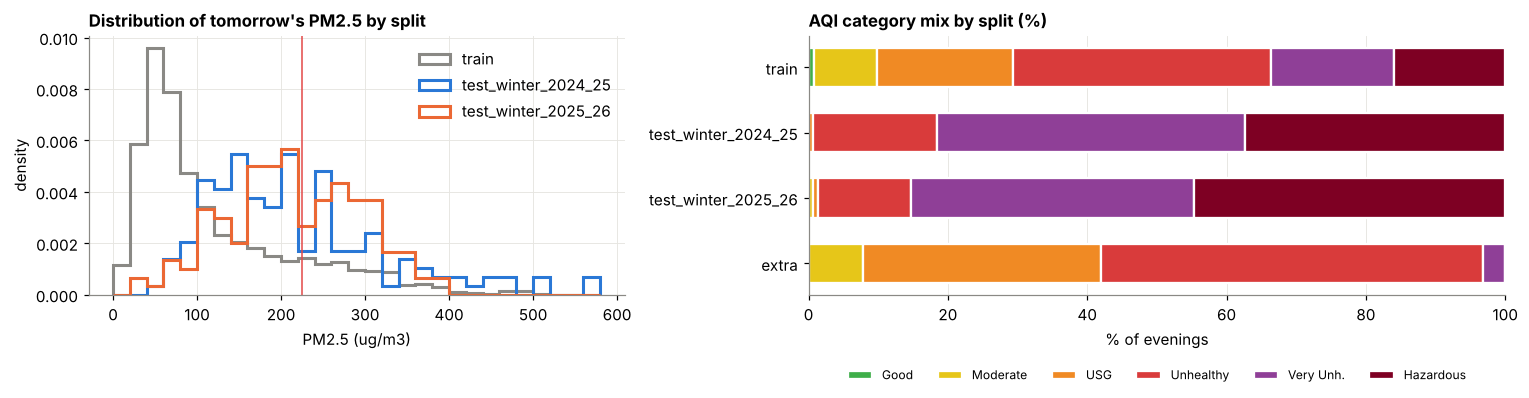

,evenings,first,last,mean_pm25_tomorrow,hazardous_days,hazardous_pct
split,,,,,,
extra,372,2025-03-01,2026-10-17,64.50,0,0.00
test_winter_2024_25,147,2024-10-01,2025-02-28,221.40,55,37.40
test_winter_2025_26,150,2025-10-01,2026-02-28,217.00,67,44.70
train,1241,2019-05-28,2024-09-30,119.90,199,16.00


In [51]:
share = (model_df.groupby("split")["aqi_category_tomorrow"].value_counts(normalize=True).unstack()
         .reindex(columns=AQI_LABELS).fillna(0) * 100)
order = ["train", "test_winter_2024_25", "test_winter_2025_26", "extra"]
share = share.reindex(order)
fig, axes = plt.subplots(1, 2, figsize=(14, 4), gridspec_kw={"width_ratios": [1, 1.3]})
for s, col in zip(["train", "test_winter_2024_25", "test_winter_2025_26"], [GREY, BLUE, ORANGE]):
    v = model_df.loc[model_df.split == s, "pm25_tomorrow"]
    axes[0].hist(v, bins=np.arange(0, 600, 20), density=True, histtype="step", lw=2, color=col, label=s)
axes[0].axvline(HAZARDOUS, color=RED, lw=1)
axes[0].set(title="Distribution of tomorrow's PM2.5 by split", xlabel="PM2.5 (ug/m3)", ylabel="density")
axes[0].legend(loc="upper right")
left = np.zeros(len(share))
for lab, short, col in zip(AQI_LABELS, AQI_SHORT, AQI_COLORS):
    axes[1].barh(share.index, share[lab], left=left, color=col, label=short, height=0.6, edgecolor="white", linewidth=1.5)
    left += share[lab].values
axes[1].invert_yaxis()
axes[1].set(title="AQI category mix by split (%)", xlabel="% of evenings", xlim=(0, 100))
axes[1].legend(loc="lower center", bbox_to_anchor=(0.5, -0.38), ncol=6, fontsize=8)
fig.tight_layout(); savefig(fig, "19_split_shift")
display(split_summary.round(1))

**Discussion:**
- **The test winters are much harder than the training set.** Training covers *all* seasons, with a mean of about 120 µg/m³ and 16 % hazardous days. The test sets are *winters only*, with means above 200 µg/m³ and **37–45 % hazardous** days.
- This is deliberate, because the winters are the use case. It means the training data's large share of clean summer days should not bias the model: in Phase 2 we will try **training on smog-season rows only, or weighting them more**, and compare.
- Winter 2025–26 is measured by **calibrated low-cost sensors**, while the training data comes mostly from the reference monitor. Good performance there would show that the calibration transfers.

# 8. Key observations and insights
The cell below computes the headline numbers directly from the data, so the text that follows can be checked against it.

In [52]:
facts = {
    "Model-ready evenings": len(model_df),
    "Trusted reference days (>= 18 h)": int(ok.sum()),
    "Calibration R2 (step 1 / step 2)": f"{fit1['r2']:.2f} / {fit2['r2']:.2f}",
    "Raw network -> reference factor": f"x {b1 * b2:.2f}",
    "Worst month (median PM2.5)": f"{month_names[int(mon.groupby('month')['pm25'].median().idxmax()) - 1]} "
                                  f"({mon.groupby('month')['pm25'].median().max():.0f} ug/m3)",
    "Cleanest month (median PM2.5)": f"{month_names[int(mon.groupby('month')['pm25'].median().idxmin()) - 1]} "
                                     f"({mon.groupby('month')['pm25'].median().min():.0f} ug/m3)",
    "Hazardous share, train / winter 24-25 / winter 25-26": " / ".join(f"{split_summary.loc[s, 'hazardous_pct']:.0f} %" for s in order[:3]),
    "Lag-1 autocorrelation of PM2.5": f"{lag_corr[0]:.2f}",
    "Persistence MAE, winter 24-25 / 25-26": f"{baseline.loc['test_winter_2024_25', 'MAE (ug/m3)']:.1f} / "
                                             f"{baseline.loc['test_winter_2025_26', 'MAE (ug/m3)']:.1f} ug/m3",
    "Oct-Nov corr. upwind fires (3 d) vs PM2.5 tomorrow": f"{fire_corr.loc['fires_upwind_last3days', 'corr. with PM2.5 tomorrow']:.2f}",
    "Oct-Nov corr. upwind fires (3 d) vs change": f"{fire_corr.loc['fires_upwind_last3days', 'corr. with change (tomorrow - today)']:.2f}",
    "Smog-season corr. boundary layer vs PM2.5 tomorrow": f"{weather_corr['boundary_layer_tomorrow']:.2f}",
    "Selected input features": len(SELECTED_FEATURES),
}
pd.Series(facts, name="value").to_frame()

,value
Model-ready evenings,1910
Trusted reference days (>= 18 h),1464
Calibration R2 (step 1 / step 2),0.89 / 0.86
Raw network -> reference factor,x 1.22
Worst month (median PM2.5),Dec (258 ug/m3)
Cleanest month (median PM2.5),Aug (47 ug/m3)
"Hazardous share, train / winter 24-25 / winter 25-26",16 % / 37 % / 45 %
Lag-1 autocorrelation of PM2.5,0.89
"Persistence MAE, winter 24-25 / 25-26",52.5 / 33.8 ug/m3
Oct-Nov corr. upwind fires (3 d) vs PM2.5 tomorrow,0.47


### What we learned

**About the data**
1. **Building the dataset was a real engineering task.** Three sources with different time steps (hourly, daily, per satellite pass), different time zones (UTC vs Pakistan time) and different quality had to be aligned. The result is a clean table of **1,910 forecasting evenings with 0 empty cells**, every step logged, plus the full daily table.
2. **The PM2.5 record has gaps (monitor outages in 2021–23, and none in spring 2025). We handled them without inventing targets:** targets are never filled; only short input gaps (≤ 2 days) are interpolated, and they are flagged.
3. **Low-cost sensors must be calibrated.** A chained linear calibration (R² 0.89 and 0.86) shows that the raw network reads about 18 % low (factor × 1.22). Without it, winter 2025–26 would look artificially cleaner.

**About Lahore's smog**
4. **It is strongly seasonal.** **December (median 258 µg/m³) and November (248)** are the worst months and August (47) is the cleanest. **37–45 % of the days in the two test winters are Hazardous**, and the three most recent winters have the highest medians in the record.
5. **Today predicts tomorrow well** (lag-1 autocorrelation 0.89). The persistence baseline has a winter MAE of **52.5 / 33.8 µg/m³** and already catches **80–85 %** of hazardous days, but it is always one day late at turning points. It is the benchmark to beat.
6. **The weather decides how much of the pollution stays.** A shallow boundary layer, calm wind, high humidity and no rain all go with much higher PM2.5. Boundary-layer height (−0.54) and wind speed (−0.40) are the strongest weather features, and December, which has few fires but the worst air, shows that the weather alone can create hazardous smog.
7. **Crop burning goes with dirtier air in Oct–Nov** (correlation of about 0.47 with tomorrow's PM2.5, and a small positive link with the *change*). Part of this is shared seasonal timing, so the **causal contribution must be tested with the Phase-2 ablation**.
8. **The burning has shifted across the border.** Indian Punjab + Haryana detections fell from about 85 thousand (2021) to 6 thousand (2025), while Pakistani Punjab stayed at 10–13 thousand. **Pakistan's share of the fires within 300 km of Lahore rose from about 13–21 % (2018–2023) to 66 % (2025).**

**For modelling (Phase 2)**
9. **Imbalanced targets:** report recall, precision and F1 for the hazardous warning, and merge the rare *Good* class.
10. **Distribution shift:** the test winters are far dirtier than the all-season training data (mean PM2.5 of about 220 vs 120 µg/m³), so we will try smog-season-only training or sample weights.

# 9. Limitations and next steps
### Limitations (and how we deal with them)
| Limitation | Effect | Our handling |
|---|---|---|
| Training uses **ERA5 "tomorrow" weather**, not a real forecast | Slightly optimistic scores (a real forecast has errors) | In the live demo we use the Open-Meteo *forecast*. In Phase 2 we will also test with noise added to the weather features. |
| Winter 2025–26 relies on **calibrated low-cost sensors** | Calibration error (MAE about 20 µg/m³) is mixed into the target | Results reported separately per `sensor_type_tomorrow` |
| **Satellite fire counts are an index**, not a census | Fires under cloud or between overpasses are missed | We use counts *and* fire power, summed over 3 days |
| 2026 **country split** uses an approximate border line | A few detections near the border may be mislabelled | Only used in the EDA, not in the selected features |
| BLH gap (Jan–Jun 2024) filled with climatology | Less precise BLH for 185 days | Flag column; Phase 2 checks the error on those rows |

### Phase 2 plan
1. **Baselines:** persistence (tomorrow = today) and climatology (the average for that calendar day).
2. **Models:** Linear/Ridge regression (with `log1p`), Random Forest, and **Histogram Gradient Boosting**, predicting the level and the change from today, with time-series cross-validation inside the training period.
3. **Three tasks:** PM2.5 regression (MAE, RMSE); AQI category (macro-F1, confusion matrix); hazardous warning (recall, precision, F1, with a tuned threshold).
4. **Research question:** an ablation study, comparing the model with and without the fire features on both test winters, plus permutation importance.
5. **Demo:** a small app that fetches today's data from the same APIs and shows tomorrow's forecast and warning.

### References
- NASA FIRMS, VIIRS 375 m active-fire products (S-NPP, NOAA-20). https://firms.modaps.eosdis.nasa.gov
- OpenAQ, open air-quality data platform and AWS archive; US Department of State AirNow (Lahore), AirGradient, Hawanama, Clarity. https://openaq.org
- Open-Meteo historical weather API, ERA5 reanalysis (Copernicus / ECMWF), CC BY 4.0. https://open-meteo.com
- US EPA (2024), *Technical Assistance Document for the Reporting of Daily Air Quality – the AQI*: PM2.5 breakpoints.
- WHO (2021), *Global Air Quality Guidelines*: 24-hour PM2.5 guideline of 15 µg/m³.